# 09 · Segmentación externa: revisión técnica y plan de análisis

## Propósito

El cuaderno 08 dejó seleccionadas las series sagitales de RSNA y Mendeley, y TotalSpineSeg realizó su segmentación en Kaggle. Este cuaderno revisa esos resultados y prepara la medición del ángulo, pero todavía no calcula ningún ángulo coronal. La razón es metodológica. Antes de examinar los resultados de RSNA y Mendeley, se deja definido y se registra públicamente en OSF el procedimiento que se seguirá, para evitar que las decisiones dependan de los ángulos obtenidos.

Aquí se revisa todo lo que puede evaluarse sin calcular esos ángulos. Se comprueban las máscaras, los errores de segmentación, la geometría y los tiempos de procesamiento. También se traducen las etiquetas a la numeración de SPIDER, se identifican las máscaras con problemas de calidad, se contrasta la numeración de los niveles con las coordenadas de RSNA y con la otra secuencia del mismo estudio, y se describe la adquisición y la muestra disponible. Por último, se comparan la T1 y la T2 mediante tres medidas técnicas y se aplica una regla definida de antemano para elegir la secuencia principal del cuaderno 10.

## Preguntas que responde

| Pregunta | Sección |
|---|---|
| ¿Cuántas series segmentó TotalSpineSeg, cuántas fallaron y cuánto tardó? | Segmentación |
| ¿Qué series de Mendeley son cervicales y qué serie lumbar del mismo estudio puede reemplazarlas? | Series cervicales de Mendeley |
| ¿Cuántas máscaras contienen los cinco discos lumbares y no presentan discos omitidos, pequeños o cortados por el campo? | Calidad de las máscaras |
| ¿La numeración de TotalSpineSeg coincide con la de los anotadores de RSNA? | Niveles frente a RSNA |
| En SPIDER, donde existe una máscara manual, ¿con qué secuencia se aproxima más TotalSpineSeg a la orientación de las caras de disco? | Exactitud en SPIDER |
| ¿Qué secuencia será la principal en el cuaderno 10? | Comparación T1 frente a T2 y regla |
| ¿La T1 y la T2 del mismo estudio asignan los mismos nombres a los discos? ¿Con qué frecuencia aparece una sexta vértebra lumbar? ¿Cómo se adquirieron las series y por qué algunos discos tocan el borde? | Comprobaciones antes del cuaderno 10 |
| ¿Cuántos estudios llegan al cuaderno 10 y qué precisión se espera para los límites de acuerdo? | Muestra para el cuaderno 10 |
| ¿Qué se medirá en el cuaderno 10 y cómo se analizarán los resultados? | Plan de análisis para OSF |

## Alcance

El análisis es técnico. En este cuaderno no se calcula ningún ángulo coronal de RSNA ni de Mendeley, ni se calculan los planos de las caras de disco de esas series. Esos planos se obtendrán en el cuaderno 10 con el mismo procedimiento utilizado en los cuadernos 03 a 07. Las únicas caras de disco examinadas aquí son las de SPIDER, que ya estaban calculadas en los cuadernos 03 y 05. SPIDER es el único conjunto que dispone de máscaras manuales y se utiliza como referencia técnica, no como parte de la muestra externa que se registrará en OSF.

Este trabajo no constituye una validación clínica ni está destinado al diagnóstico de escoliosis.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos. Por esa razón, las tablas por estudio, serie o punto se conservan en carpetas privadas de Drive y no se publican. En la carpeta de resultados solo se incluyen resúmenes agregados. Mendeley (CC BY 4.0) y SPIDER (CC BY 4.0) sí permiten conservar tablas por serie.

## Segmentación

Las máscaras se generaron mediante tres cuadernos auxiliares de Kaggle, todos con el paquete de TotalSpineSeg 20260807 y los mismos pesos r20260730, verificados mediante su huella. Las máscaras de Mendeley proceden del cuaderno auxiliar del 08, que procesó las listas A y B. Las de RSNA se generaron con `09_tss_kaggle_rsna`. Este cuaderno lee los vóxeles de la misma manera que el 08, pero recupera el espaciado, el origen y la dirección desde las cabeceras DICOM. Esto es necesario porque, al leer las cabeceras anonimizadas con GDCM, la imagen queda sin su espaciado ni su origen originales. Las series lumbares de Mendeley que sustituyen a las cervicales, identificadas en la celda 6, proceden de `09_tss_kaggle_mendeley`.

## Fuentes

- **Máscaras de TotalSpineSeg**, generadas en Kaggle a partir de las series y las listas preparadas en el cuaderno 08.

- **RSNA LumbarDISC.** Coordenadas de nivel de `train_label_coordinates.csv` e inventario de imágenes del cuaderno 08, conservados en copias privadas. Competición [RSNA 2024 Lumbar Spine Degenerative Classification](https://www.kaggle.com/competitions/rsna-2024-lumbar-spine-degenerative-classification). Uso no comercial y sin redistribución.

- **Lumbar Spine MRI Dataset** de Mendeley, de Sudirman *et al.* ([doi:10.17632/k57fr854j2.2](https://doi.org/10.17632/k57fr854j2.2), CC BY 4.0), con la selección, la conversión y el inventario del cuaderno 08.

- **SPIDER.** Máscaras manuales (`masks.zip`, verificadas contra Zenodo en el cuaderno 03), planos de las caras de disco de las máscaras manuales (cuaderno 03) y de TotalSpineSeg (cuaderno 05), e inventario del cuaderno 01. Artículo del conjunto: van der Graaf *et al.*, Scientific Data 2024 ([arXiv:2306.12217](https://arxiv.org/abs/2306.12217)).

- **Etiquetas de TotalSpineSeg.** [neuropoly/totalspineseg](https://github.com/neuropoly/totalspineseg). Las vértebras L1 a L5 corresponden a las etiquetas 41 a 45 y L6 a la 46. El sacro corresponde a la 50. Los discos T12-L1 a L4-L5 corresponden a las etiquetas 91 a 95, L5-L6 a la 96 y el último disco lumbar con el sacro a la 100, según `tss_map.json` e `inference.py` del repositorio.

## Antes de ejecutar: datos necesarios

Este cuaderno se ejecuta en Colab y no necesita GPU. Para correrlo se requieren los siguientes archivos en Google Drive.

| Archivo | Ruta en Google Drive |
|---|---|
| `lista_A.csv` y `lista_B.csv` del cuaderno 08 | `MyDrive/PRL/content/datos/segmentacion_08/listas/` |
| Máscaras, registros y entornos de Mendeley (`mascaras_mendeley_*.zip`, `registro_mendeley_*.csv`, `entorno_mendeley_*.json`) y `lista_mendeley_lumbares.csv` | `MyDrive/PRL/content/datos/segmentacion_tss/mendeley/` |
| Máscaras, registros, geometría y entornos de RSNA (`mascaras_rsna_*.zip`, `registro_rsna_*.csv`, `geometria_rsna_*.csv`, `entorno_rsna_*.json`) | `MyDrive/PRL/content/datos/segmentacion_tss/rsna/` |
| `train_label_coordinates.csv` e `imagenes_rsna.csv.gz` | `MyDrive/PRL/content/datos/rsna/inventario/` |
| `seleccion_mendeley.csv`, `conversion_mendeley.csv` y `mendeley_inventario/series_mendeley.csv` del cuaderno 08 | `MyDrive/PRL/salidas/resultados_semana4/08_rsna_y_mendeley/` |
| NIfTI de Mendeley del cuaderno 08 | `MyDrive/PRL/content/datos/mendeley/nifti_sagital/` |
| `inventario_series.csv` | `MyDrive/PRL/salidas/resultados_semana1/01_INVENTARIO_SPIDER/` |
| `planos_por_disco.csv` | `MyDrive/PRL/salidas/resultados_semana2/03_disco_caudal_y_variantes/` |
| `planos_por_disco_tss.csv` | `MyDrive/PRL/salidas/resultados_semana3/05_segmentacion_automatica/` |
| `masks.zip` y las máscaras de TotalSpineSeg en `convencion_spider/`, necesarias solo para calcular el Dice | `MyDrive/PRL/content/datos/spider/masks/` y `MyDrive/PRL/content/datos/AutoSegments/tss/` |

El recorrido de las máscaras, realizado en la celda 5, tarda unos 40 minutos. El avance se guarda en Drive por tandas, por lo que, si Colab se interrumpe, basta con volver a ejecutar el cuaderno desde el principio. Las tablas privadas se guardan en `content/datos/analisis_09/`. Las máscaras traducidas a la numeración de SPIDER, que utilizará el cuaderno 10, se guardan en `content/datos/segmentacion_tss/traducidas/`.

Si se ejecuta desde cero y todavía no existe `lista_mendeley_lumbares.csv`, la celda 6 genera esa lista y deja junto a ella un archivo ZIP con los NIfTI correspondientes para segmentarlos mediante `09_tss_kaggle_mendeley`. En ese punto, el cuaderno se detiene. Una vez guardadas las salidas de ese procesamiento en `segmentacion_tss/mendeley/`, se puede continuar con el resto del análisis.

In [2]:
# 1. Dependencias
!pip -q install SimpleITK

In [3]:
# 2. Configuración
import os, re, io, json, time, shutil, zipfile, hashlib, tempfile, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
from scipy import ndimage
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_DATOS = DIR_PRL / "content" / "datos"
DIR_SEG = DIR_DATOS / "segmentacion_08"
DIR_LISTAS = DIR_SEG / "listas"
DIR_TSS = DIR_DATOS / "segmentacion_tss"                             # privado: salidas de TotalSpineSeg
DIR_TSS_MEN, DIR_TSS_RSNA = DIR_TSS / "mendeley", DIR_TSS / "rsna"
DIR_TRADUCIDAS = DIR_TSS / "traducidas"                              # máscaras en la numeración de SPIDER, un zip por tanda
CSV_LISTA_LUMBARES = DIR_TSS_MEN / "lista_mendeley_lumbares.csv"     # series lumbares que reemplazan a las cervicales
DIR_NIFTI_MENDELEY = DIR_DATOS / "mendeley" / "nifti_sagital"        # NIfTI de Mendeley convertidos en el cuaderno 08
DIR_PRIV = DIR_DATOS / "analisis_09"                                 # privado: tablas por estudio, serie y punto
DIR_PRIVADO_RSNA = DIR_DATOS / "rsna" / "inventario"
CSV_COORD_RSNA = DIR_PRIVADO_RSNA / "train_label_coordinates.csv"
CSV_IMAGENES_RSNA = DIR_PRIVADO_RSNA / "imagenes_rsna.csv.gz"
SALIDAS = DIR_PRL / "salidas"
CSV_INVENTARIO_01 = SALIDAS / "resultados_semana1" / "01_INVENTARIO_SPIDER" / "inventario_series.csv"
CSV_PLANOS_MANUAL_03 = SALIDAS / "resultados_semana2" / "03_disco_caudal_y_variantes" / "planos_por_disco.csv"
CSV_PLANOS_TSS_05 = SALIDAS / "resultados_semana3" / "05_segmentacion_automatica" / "planos_por_disco_tss.csv"
DIR_SALIDA_08 = SALIDAS / "resultados_semana4" / "08_rsna_y_mendeley"
CSV_SELECCION_MENDELEY_08 = DIR_SALIDA_08 / "seleccion_mendeley.csv"
CSV_CONVERSION_MENDELEY_08 = DIR_SALIDA_08 / "conversion_mendeley.csv"
CSV_SERIES_MENDELEY_08 = DIR_SALIDA_08 / "mendeley_inventario" / "series_mendeley.csv"
ZIP_MASCARAS_SPIDER = DIR_DATOS / "spider" / "masks" / "masks.zip"
DIR_TSS_SPIDER = DIR_DATOS / "AutoSegments" / "tss" / "convencion_spider"
DIR_SALIDA = SALIDAS / "resultados_semana4" / "09_segmentacion_externa"   # público: solo agregados de RSNA
DIR_LOCAL = Path("/content/datos09")                                       # disco temporal de Colab

# Parámetros
B_BOOTSTRAP, SEMILLA = 2000, 2026          # como en los cuadernos 05 a 07
UMBRAL_SALTO = 1.5                         # cuaderno 05: salto entre discos consecutivos > 1,5 veces la mediana
FRACCION_DISCO_PEQUENO = 0.25              # cuaderno 05: disco con menos del 25 % de los vóxeles de la mediana
UMBRAL_PAREJA_MM = 10.0                    # cuaderno 05: emparejamiento de discos por posición
MM_POR_INDICE = 0.5                        # cuaderno 05: espacio del script (vóxeles de 0,5 mm)
DISTANCIA_RADIAL_MAX_MM = 40.0             # punto de RSNA a más de esto del eje de la columna: "sin disco cercano"
TAMANO_TANDA = 200                         # máscaras por tanda en el recorrido (guarda avance en Drive)
CALCULAR_DICE = True                       # Dice de discos y canal en SPIDER (lee 2 × ~300 máscaras de Drive)
MAX_PAREJA_T1_T2_MM = 15.0                 # discos de la T1 y la T2 del mismo estudio a menos de esto son el mismo disco
NIVEL_RSNA_A_TSS = {"L1/L2": 92, "L2/L3": 93, "L3/L4": 94, "L4/L5": 95, "L5/S1": 100}
DISCOS_LUMBARES = [92, 93, 94, 95, 100]    # L1-L2 a L5-S en TotalSpineSeg
# Discos de TotalSpineSeg de craneal a caudal: C2-C3 … C6-C7 (63–67), C7-T1 (71), T1-T2 … T11-T12 (72–82),
# T12-L1 (91), L1-L2 … L4-L5 (92–95), L5-L6 (96, solo con sexta lumbar) y último lumbar con el sacro (100)
DISCOS_EN_ORDEN = [63, 64, 65, 66, 67, 71, *range(72, 83), 91, 92, 93, 94, 95, 96, 100]
ORDEN_DISCO = {d: k for k, d in enumerate(DISCOS_EN_ORDEN)}
NOMBRE_TSS = {**{40 + i: f"L{i}" for i in range(1, 7)}, 50: "sacro",
              91: "T12-L1", 92: "L1-L2", 93: "L2-L3", 94: "L3-L4", 95: "L4-L5", 96: "L5-L6", 100: "L5-S"}

for d in (DIR_SALIDA, DIR_PRIV, DIR_LOCAL, DIR_TRADUCIDAS):
    d.mkdir(parents=True, exist_ok=True)
for archivo in (DIR_LISTAS / "lista_A.csv", DIR_LISTAS / "lista_B.csv", CSV_COORD_RSNA, CSV_IMAGENES_RSNA,
                CSV_INVENTARIO_01, CSV_PLANOS_MANUAL_03, CSV_PLANOS_TSS_05, CSV_SELECCION_MENDELEY_08,
                CSV_CONVERSION_MENDELEY_08, CSV_SERIES_MENDELEY_08):
    assert archivo.exists(), f"Falta {archivo}: revisa la tabla de datos necesarios"
for carpeta, patron in ((DIR_TSS_MEN, "registro_mendeley_*.csv"), (DIR_TSS_MEN, "mascaras_mendeley_*.zip"),
                        (DIR_TSS_RSNA, "registro_rsna_*.csv"), (DIR_TSS_RSNA, "mascaras_rsna_*.zip"),
                        (DIR_TSS_RSNA, "geometria_rsna_*.csv")):
    assert list(carpeta.glob(patron)), f"No hay {patron} en {carpeta}: revisa la tabla de datos necesarios"
listas = pd.concat([pd.read_csv(p, dtype={"estudio": str, "serie_clave": str})
                    for p in (DIR_LISTAS / "lista_A.csv", DIR_LISTAS / "lista_B.csv", CSV_LISTA_LUMBARES) if p.exists()],
                   ignore_index=True)
print(listas.groupby(["lista", "conjunto"]).agg(estudios=("estudio", "nunique"), series=("id_serie", "size")).to_string())
print("Salida pública:", DIR_SALIDA)
print("Salida privada:", DIR_PRIV)

Mounted at /content/drive
                   estudios  series
lista    conjunto                  
A        mendeley       258     516
         rsna           988    1975
B        mendeley       257     514
         rsna           987    1972
lumbares mendeley        21      44
Salida pública: /content/drive/MyDrive/PRL/salidas/resultados_semana4/09_segmentacion_externa
Salida privada: /content/drive/MyDrive/PRL/content/datos/analisis_09


## Segmentación

La celda 3 cruza tres fuentes para Mendeley y RSNA: las series incluidas en las listas, los registros de Kaggle que indican si la segmentación terminó correctamente y las máscaras que realmente están guardadas en los archivos ZIP. También resume los errores por tipo, sin mostrar identificadores, identifica las huellas de volumen que no coinciden con las del cuaderno 08, comprueba si la geometría de cada máscara corresponde a la de su imagen y resume el tiempo de procesamiento. Para RSNA, además, compara la geometría que devuelve GDCM con la recuperada directamente de las cabeceras DICOM.

In [4]:
# 3. Registros frente a las listas y frente a las máscaras, errores, huellas, geometría y duración
def leer_registros(carpeta, patron):
    return pd.concat([pd.read_csv(p, dtype=str).assign(archivo=p.stem) for p in sorted(carpeta.glob(patron))],
                     ignore_index=True)

def indice_de_mascaras(carpeta, patron):
    "{id_serie: (zip, nombre)} con todas las máscaras de los zip."
    indice = {}
    for zm in sorted(carpeta.glob(patron)):
        with zipfile.ZipFile(zm) as z:
            for n in z.namelist():
                indice[n.split(".nii")[0]] = (zm, n)
    return indice

def tipo_error(t):
    t = str(t)
    return "entrada: " + t.split(":")[1].strip() if t.startswith("error de entrada") else "TotalSpineSeg sin salida"

reg_todas = pd.concat([leer_registros(DIR_TSS_MEN, "registro_mendeley_*.csv"),
                       leer_registros(DIR_TSS_RSNA, "registro_rsna_*.csv")], ignore_index=True)
reg_todas["es_ok"] = reg_todas["estado"] == "ok"
reg_todas["seg_por_serie"] = pd.to_numeric(reg_todas["segundos_lote"]) / pd.to_numeric(reg_todas["series_en_lote"])
registro = reg_todas.sort_values(["es_ok", "fecha"]).drop_duplicates("id_serie", keep="last").set_index("id_serie")
mascaras = {**indice_de_mascaras(DIR_TSS_MEN, "mascaras_mendeley_*.zip"),
            **indice_de_mascaras(DIR_TSS_RSNA, "mascaras_rsna_*.zip")}
assert not (set(mascaras) - set(listas["id_serie"])), "Hay máscaras de series que no están en las listas"

filas_resumen, filas_errores = [], []
for (lista, conjunto), g in listas.groupby(["lista", "conjunto"]):
    r = registro.reindex(g["id_serie"]).dropna(subset=["estado"])
    ok = set(r.index[r["es_ok"].astype(bool)])
    t = reg_todas[reg_todas["id_serie"].isin(g["id_serie"])]
    fechas = pd.to_datetime(t["fecha"])
    horas = sum((f.max() - f.min()).total_seconds() for _, f in fechas.groupby(t["archivo"])) / 3600
    filas_resumen.append({
        "lista": lista, "conjunto": conjunto, "en_lista": len(g), "en_registro": len(r), "ok": len(ok),
        "error": len(r) - len(ok), "sin_registro": len(g) - len(r), "ok_sin_mascara": len(ok - set(mascaras)),
        "huella_distinta": int((r["huella_ok"] == "False").sum()), "geometria_distinta": int((r["geometria_ok"] == "False").sum()),
        "seg_por_serie_gpu_mediana": round(t["seg_por_serie"].median(), 1), "horas_de_reloj": round(horas, 2)})
    for tipo, n in r.loc[~r["es_ok"].astype(bool), "error"].map(tipo_error).value_counts().items():
        filas_errores.append({"lista": lista, "conjunto": conjunto, "tipo": tipo, "series": int(n)})
resumen_kaggle = pd.DataFrame(filas_resumen)
resumen_kaggle.to_csv(DIR_SALIDA / "kaggle_resumen.csv", index=False)
display(resumen_kaggle)
errores_kaggle = pd.DataFrame(filas_errores, columns=["lista", "conjunto", "tipo", "series"])
errores_kaggle.to_csv(DIR_SALIDA / "kaggle_errores_por_tipo.csv", index=False)
print("Errores por tipo (sin identificadores):")
print(errores_kaggle.to_string(index=False) if len(errores_kaggle) else "ninguno")
con_mascara = sorted(i for i in registro.index[registro["es_ok"].astype(bool)] if i in mascaras)
print(f"\nMáscaras disponibles para el resto del cuaderno: {len(con_mascara)} de {len(listas)} series de las listas")

for e in sorted([*DIR_TSS_MEN.glob("entorno_*.json"), *DIR_TSS_RSNA.glob("entorno_*.json")]):
    entorno_k = json.loads(e.read_text())
    print(f"{e.name}: GPU {entorno_k.get('gpu_nombre')} x{entorno_k.get('gpus')}, TotalSpineSeg {entorno_k.get('totalspineseg')}, "
          f"pesos {entorno_k.get('pesos_release')}, lote {entorno_k.get('tam_lote')}")

# Geometría de RSNA: lo que daba la lectura con GDCM y lo que se tomó de las cabeceras
geometria = pd.concat([pd.read_csv(p) for p in sorted(DIR_TSS_RSNA.glob("geometria_rsna_*.csv"))],
                      ignore_index=True).drop_duplicates("id_serie", keep="last")
geometria.to_csv(DIR_PRIV / "geometria_rsna_por_serie.csv", index=False)
resumen_geometria = pd.DataFrame({
    "series": [len(geometria)],
    "gdcm_espaciado_1mm_pct": [round(100 * (geometria["espaciado_gdcm"] == "1.000x1.000x1.000").mean(), 1)],
    "gdcm_origen_cero_pct": [round(100 * geometria["origen_gdcm_cero"].astype(bool).mean(), 1)],
    "paso_irregular_pct": [round(100 * geometria["paso_irregular"].astype(bool).mean(), 1)],
    "espaciado_plano_mm_mediana": [round(geometria["espaciado_i"].median(), 3)],
    "paso_cortes_mm_mediana": [round(geometria["paso_cortes"].median(), 2)]})
resumen_geometria.to_csv(DIR_SALIDA / "geometria_rsna_resumen.csv", index=False)
print("Geometría de RSNA (la que daba GDCM y la que se tomó de las cabeceras):")
display(resumen_geometria)

,lista,conjunto,en_lista,en_registro,ok,error,sin_registro,ok_sin_mascara,huella_distinta,geometria_distinta,seg_por_serie_gpu_mediana,horas_de_reloj
0,A,mendeley,516,516,514,2,0,0,8,0,25.6,1.80
1,A,rsna,1975,1975,1974,1,0,0,0,0,27.5,8.17
2,B,mendeley,514,514,511,3,0,0,6,0,24.4,1.72
3,B,rsna,1972,1972,1972,0,0,0,0,0,27.2,8.07
4,lumbares,mendeley,44,44,44,0,0,0,0,0,27.1,0.04


Errores por tipo (sin identificadores):
lista conjunto                     tipo  series
    A mendeley TotalSpineSeg sin salida       2
    A     rsna    entrada: RuntimeError       1
    B mendeley TotalSpineSeg sin salida       3

Máscaras disponibles para el resto del cuaderno: 5015 de 5021 series de las listas
entorno_mendeley_A.json: GPU Tesla T4 x2, TotalSpineSeg 20260807, pesos r20260730, lote 20
entorno_mendeley_B.json: GPU Tesla T4 x2, TotalSpineSeg 20260807, pesos r20260730, lote 20
entorno_mendeley_lumbares.json: GPU Tesla T4 x2, TotalSpineSeg 20260807, pesos r20260730, lote 20
entorno_rsna_A.json: GPU Tesla T4 x2, TotalSpineSeg 20260807, pesos r20260730, lote 20
entorno_rsna_B.json: GPU Tesla T4 x2, TotalSpineSeg 20260807, pesos r20260730, lote 20
Geometría de RSNA (la que daba GDCM y la que se tomó de las cabeceras):


,series,gdcm_espaciado_1mm_pct,gdcm_origen_cero_pct,paso_irregular_pct,espaciado_plano_mm_mediana,paso_cortes_mm_mediana
0,3946,100.0,100.0,0.1,0.647,4.48


**Cómo leer la salida de la celda 3.** La primera tabla separa los resultados por conjunto y lista. `en_lista` indica cuántas series se enviaron a segmentar, `ok` cuántas aparecen como correctas en el registro y `ok_sin_mascara` cuántas figuran como correctas en el registro, pero no tienen una máscara dentro de los ZIP. Este último valor debería ser cero. `huella_distinta` cuenta las series cuya imagen reconstruida en Kaggle no conserva la misma huella de vóxeles y geometría que la imagen del cuaderno 08. `geometria_distinta` identifica las máscaras cuya rejilla no coincide con la de su imagen. El tiempo se presenta en segundos por serie, mediante la mediana de cada GPU, y como tiempo total de reloj. La última tabla resume la geometría de las series de RSNA.

**Resultados.** En Mendeley se generaron máscaras para 1.025 de las 1.030 series de las listas A y B, además de las 44 series lumbares candidatas identificadas en la celda 6. En 14 series, la huella de la imagen reconstruida en Kaggle no coincidió con la del cuaderno 08. Sin embargo, la geometría de todas las máscaras sí coincide con la de su imagen. La explicación más probable es una diferencia al volver a leer el archivo NIfTI, aunque no se comprobó la correspondencia vóxel por vóxel.

En RSNA se generaron máscaras para 3.946 de las 3.947 series. La serie restante no se pudo convertir. La huella de las imágenes coincidió con la del cuaderno 08 en todas las series procesadas y ninguna máscara presentó una geometría distinta de la imagen correspondiente. Esto confirma que se segmentaron los mismos vóxeles seleccionados en el cuaderno 08.

La tabla de geometría también muestra por qué fue necesario recuperar los datos directamente de las cabeceras DICOM. GDCM dejó el 100 % de las series con un espaciado de 1 mm y el origen en cero, mientras que las cabeceras originales indican una mediana de 0,647 mm en el plano y 4,48 mm entre cortes. Solo el 0,1 % de las series presenta un paso entre cortes irregular. En cada GPU, TotalSpineSeg tardó una mediana de entre 24 y 27 segundos por serie.

## Traducción y recorrido de las máscaras

La celda 4 define las funciones y la celda 5 recorre todas las máscaras correctas por tandas. De cada máscara se guarda una fila por etiqueta con la estructura correspondiente, el número de vóxeles, su centro en milímetros dentro del sistema del paciente (LPS) y la indicación de si toca alguno de los bordes lateral, craneal o caudal del campo de visión.

Además, cada máscara se traduce a la numeración de SPIDER mediante la misma función utilizada en el cuaderno 05. Las vértebras se numeran como 1, 2 y siguientes, y los discos como 201, 202 y siguientes, de caudal a craneal. El canal y la médula se identifican con la etiqueta 100, mientras que el sacro queda fuera de esta traducción. Las máscaras traducidas se guardan en archivos ZIP privados, uno por tanda, para que el cuaderno 10 pueda calcular las caras de disco. La tabla de traducción conserva también la etiqueta anatómica original de cada estructura.

Los ejes de cada máscara se identifican a partir de su matriz de dirección, no del orden de los ejes en el arreglo. Esto es importante porque las series no siempre tienen la misma orientación. Se identifica como eje lateral el que apunta principalmente de izquierda a derecha y como eje craneal el que apunta de abajo hacia arriba. La celda 5 comprueba, además, que ninguna máscara tenga un espaciado de 1 × 1 × 1 mm y origen en cero, combinación que indicaría que la imagen se leyó sin conservar su geometría original.

In [5]:
# 4. Funciones: ejes, recorrido de una máscara y traducción a la convención de SPIDER (igual que en el cuaderno 05)
def tipo_tss(l):
    "Clase de cada etiqueta de TotalSpineSeg: médula 1, canal 2, vértebras 11–45, sacro 50, discos 63–100."
    return "disco" if 60 <= l <= 100 else "canal" if l in (1, 2) else "sacro" if l == 50 else "vertebra"

def ejes(img):
    "Ejes de índice (de SimpleITK) lateral, anteroposterior y craneocaudal, y la matriz de dirección."
    D = np.array(img.GetDirection()).reshape(3, 3)          # D[k, i]: componente física k del eje de índice i
    i_lr, i_ap, i_si = (int(np.argmax(np.abs(D[k, :]))) for k in range(3))
    assert len({i_lr, i_ap, i_si}) == 3, "No se pudieron asignar los ejes de la imagen"
    return D, i_lr, i_ap, i_si

def recorrer_mascara(img):
    "Una fila por etiqueta: tipo, vóxeles, centro en mm (LPS) y si toca los bordes del campo; y el eje lateral."
    arr = sitk.GetArrayFromImage(img).astype(np.int32)      # copia propia (ejes de numpy: z, y, x)
    D, i_lr, i_ap, i_si = ejes(img)
    ax_lr, ax_si = 2 - i_lr, 2 - i_si
    craneal_al_final = D[2, i_si] > 0                      # en LPS, +z es craneal
    etiquetas = [int(l) for l in np.unique(arr) if l != 0]
    if not etiquetas:
        return [], D[:, i_lr]
    cajas = ndimage.find_objects(arr)
    centros = ndimage.center_of_mass(np.ones(arr.shape, dtype=np.uint8), labels=arr, index=etiquetas)
    voxeles = np.bincount(arr.ravel())
    filas = []
    for l, c in zip(etiquetas, centros):
        caja = cajas[l - 1]
        p = img.TransformContinuousIndexToPhysicalPoint(tuple(float(v) for v in c[::-1]))
        toca_final = caja[ax_si].stop == arr.shape[ax_si]
        toca_inicio = caja[ax_si].start == 0
        filas.append({"etiqueta": l, "tipo": tipo_tss(l), "nombre": NOMBRE_TSS.get(l, ""), "voxeles": int(voxeles[l]),
                      "x_mm": p[0], "y_mm": p[1], "z_mm": p[2],
                      "toca_borde_lateral": bool(caja[ax_lr].start == 0 or caja[ax_lr].stop == arr.shape[ax_lr]),
                      "toca_borde_craneal": bool(toca_final if craneal_al_final else toca_inicio),
                      "toca_borde_caudal": bool(toca_inicio if craneal_al_final else toca_final),
                      "cortes_lr_con_etiqueta": int(caja[ax_lr].stop - caja[ax_lr].start)})
    return filas, D[:, i_lr]

def etiquetas_y_alturas(mascara):
    "Etiquetas presentes y altura física (mm) del centroide de cada una; en LPS, +z es craneal. (Cuaderno 05)"
    arr = sitk.GetArrayViewFromImage(mascara)
    etiquetas = [int(l) for l in np.unique(arr) if l != 0]
    centros = ndimage.center_of_mass(np.ones(arr.shape, dtype=np.uint8), labels=arr, index=etiquetas)
    return etiquetas, {l: mascara.TransformContinuousIndexToPhysicalPoint(tuple(float(v) for v in c[::-1]))[2]
                       for l, c in zip(etiquetas, centros)}

def traducir_a_spider(mascara, segmentador):
    """Renumera una máscara automática a la convención de SPIDER, ordenando por la altura del centroide:
    vértebras 1, 2, ... y discos 201, 202, ... de caudal a craneal; canal (y médula) = 100; sacro fuera.
    Devuelve la máscara traducida y una tabla con la equivalencia de cada etiqueta. (Cuaderno 05, sin cambios)"""
    arr = sitk.GetArrayFromImage(mascara)
    etiquetas, alturas = etiquetas_y_alturas(mascara)
    voxeles = np.bincount(arr.ravel().astype(np.int64))
    if segmentador == "iis":            # vértebras 1–24 y 101–124 (incompletas), canal 100, discos 201–224
        tipo = {l: "disco" if l > 200 else "canal" if l == 100 else "vertebra" for l in etiquetas}
    elif segmentador == "tss":          # médula 1, canal 2, vértebras 11–45, sacro 50, discos 63–100
        tipo = {l: "disco" if 60 <= l <= 100 else "canal" if l in (1, 2) else "sacro" if l == 50 else "vertebra"
                for l in etiquetas}
    else:
        raise ValueError(segmentador)
    lut = {l: 100 for l in etiquetas if tipo[l] == "canal"}
    lut.update({l: k for k, l in enumerate(sorted((l for l in etiquetas if tipo[l] == "vertebra"), key=alturas.get), 1)})
    lut.update({l: k for k, l in enumerate(sorted((l for l in etiquetas if tipo[l] == "disco"), key=alturas.get), 201)})
    salida = np.zeros(arr.shape, dtype=np.uint16)
    for l, nueva in lut.items():
        salida[arr == l] = nueva
    traducida = sitk.GetImageFromArray(salida)
    traducida.CopyInformation(mascara)
    vox_discos = [voxeles[l] for l in etiquetas if tipo[l] == "disco"]
    mediana_discos = float(np.median(vox_discos)) if vox_discos else np.nan
    tabla = [{"etiqueta_original": l, "tipo": tipo[l], "etiqueta_spider": lut.get(l, 0),
              "altura_mm": round(alturas[l], 2), "voxeles": int(voxeles[l]),
              "disco_pequeno": bool(tipo[l] == "disco" and voxeles[l] < 0.25 * mediana_discos)}
             for l in etiquetas]
    return traducida, tabla

def anotar(csv, filas):
    if filas:
        pd.DataFrame(filas).to_csv(csv, mode="a", header=not csv.exists(), index=False)

print("Funciones listas.")

Funciones listas.


In [6]:
# 5. Recorrido de todas las máscaras correctas, por tandas (retoma donde iba)
CSV_ETIQUETAS = DIR_PRIV / "etiquetas_por_mascara.csv"
CSV_TRADUCCION = DIR_PRIV / "traduccion_etiquetas.csv"
CSV_REG_RECORRIDO = DIR_PRIV / "registro_recorrido.csv"
datos_lista = listas.set_index("id_serie")[["lista", "conjunto", "estudio", "clase"]]

hechas = set(pd.read_csv(CSV_REG_RECORRIDO, dtype=str)["id_serie"]) if CSV_REG_RECORRIDO.exists() else set()
inicio = time.time()
pendientes = [i for i in con_mascara if i not in hechas]
print(f"Máscaras pendientes: {len(pendientes)}")
# Los zip de máscaras se leen desde una copia en el disco de Colab, mucho más rápido que leerlos en Drive
for i in pendientes:
    zm, n = mascaras[i]
    local = DIR_LOCAL / zm.name
    if not local.exists() or local.stat().st_size != zm.stat().st_size:
        shutil.copy(zm, local)
    mascaras[i] = (local, n)
tandas = [pendientes[k:k + TAMANO_TANDA] for k in range(0, len(pendientes), TAMANO_TANDA)]
for nt, tanda in enumerate(tandas, 1):
    dir_tanda = DIR_LOCAL / "tanda"
    shutil.rmtree(dir_tanda, ignore_errors=True)
    dir_tanda.mkdir(parents=True)
    filas_et, filas_tr, filas_reg = [], [], []
    por_zip = {}
    for i in tanda:
        por_zip.setdefault(mascaras[i][0], []).append(i)
    for zm, ids in por_zip.items():
        with zipfile.ZipFile(zm) as z:
            for i in ids:
                t0, estado, error, e_lr, geo = time.time(), "ok", "", (np.nan, np.nan, np.nan), {}
                try:
                    ruta = dir_tanda / mascaras[i][1]
                    ruta.write_bytes(z.read(mascaras[i][1]))
                    img = sitk.ReadImage(str(ruta))
                    filas, e_lr = recorrer_mascara(img)
                    _, i_lr, _, _ = ejes(img)
                    geo = {"esp_x": img.GetSpacing()[0], "esp_y": img.GetSpacing()[1], "esp_z": img.GetSpacing()[2],
                           "origen_cero": bool(np.allclose(img.GetOrigin(), 0)), "cortes_lr": img.GetSize()[i_lr],
                           "esp_lr": img.GetSpacing()[i_lr]}
                    if not filas:
                        estado = "vacia"
                    filas_et += [{"id_serie": i, **f} for f in filas]
                    traducida, tabla = traducir_a_spider(img, "tss")
                    sitk.WriteImage(traducida, str(dir_tanda / f"{i}.mha"), useCompression=True)
                    filas_tr += [{"id_serie": i, **f} for f in tabla]
                    ruta.unlink()
                except Exception as e:
                    estado, error = "error", f"{type(e).__name__}: {e}"[:300]
                filas_reg.append({"id_serie": i, "estado": estado, "error": error,
                                  "lr_x": e_lr[0], "lr_y": e_lr[1], "lr_z": e_lr[2], **geo,
                                  "segundos": round(time.time() - t0, 2)})
    # La tanda se guarda entera: primero su zip de máscaras traducidas y después las tablas (que marcan lo hecho)
    zip_local = DIR_LOCAL / "traducidas.zip"
    zip_local.unlink(missing_ok=True)
    with zipfile.ZipFile(zip_local, "w", zipfile.ZIP_STORED) as z:   # las .mha ya van comprimidas
        for f in sorted(dir_tanda.glob("*.mha")):
            z.write(f, f.name)
    n_zip = len(list(DIR_TRADUCIDAS.glob("tanda_*.zip"))) + 1
    shutil.copy(zip_local, DIR_TRADUCIDAS / f"tanda_{n_zip:03d}.zip")
    anotar(CSV_ETIQUETAS, filas_et)
    anotar(CSV_TRADUCCION, filas_tr)
    anotar(CSV_REG_RECORRIDO, filas_reg)
    print(f"  tanda {nt}/{len(tandas)} | {(time.time() - inicio) / 60:.1f} min")

reg_rec = pd.read_csv(CSV_REG_RECORRIDO, dtype={"id_serie": str}).drop_duplicates("id_serie", keep="last")
etiquetas = pd.read_csv(CSV_ETIQUETAS, dtype={"id_serie": str}).drop_duplicates(["id_serie", "etiqueta"], keep="last")
etiquetas = etiquetas[etiquetas["id_serie"].isin(reg_rec["id_serie"])]
print(f"\nMáscaras recorridas: {len(reg_rec)} | estados: {reg_rec['estado'].value_counts().to_dict()} | "
      f"segundos por máscara (mediana): {reg_rec['segundos'].median():.2f}")
reg_rec["conjunto"] = reg_rec["id_serie"].map(datos_lista["conjunto"])
deformadas = reg_rec[np.isclose(reg_rec[["esp_x", "esp_y", "esp_z"]], 1.0).all(axis=1) & reg_rec["origen_cero"].astype(bool)]
print("Máscaras con espaciado 1 × 1 × 1 mm y origen en cero, por conjunto:",
      deformadas.groupby("conjunto").size().reindex(["mendeley", "rsna"], fill_value=0).to_dict())
assert deformadas.empty, "Hay máscaras con espaciado 1 × 1 × 1 mm y origen en cero: revisa de qué zip salieron"
print("Etiquetas de TotalSpineSeg más frecuentes (número de máscaras que las traen):")
print(etiquetas.groupby(["tipo", "etiqueta"])["id_serie"].nunique().sort_values(ascending=False).head(25).to_string())

Máscaras pendientes: 0

Máscaras recorridas: 5015 | estados: {'ok': 5015} | segundos por máscara (mediana): 0.47
Máscaras con espaciado 1 × 1 × 1 mm y origen en cero, por conjunto: {'mendeley': 0, 'rsna': 0}
Etiquetas de TotalSpineSeg más frecuentes (número de máscaras que las traen):
tipo      etiqueta
canal     2           5015
          1           5014
disco     94          4972
          95          4972
vertebra  44          4972
sacro     50          4972
vertebra  45          4971
          43          4971
disco     93          4971
          92          4970
vertebra  41          4970
          42          4970
disco     91          4969
vertebra  32          4969
disco     100         4967
          82          4215
vertebra  31          4104
disco     81          1512
vertebra  30          1410
disco     80           289
vertebra  29           273
disco     79            45
vertebra  12            43
          11            43
disco     63            43


## Series cervicales de Mendeley

En algunos estudios de Mendeley hay series sagitales cervicales y lumbares con la misma descripción, por ejemplo `t1_tse_sag_384`. La selección del cuaderno 08 se basó en la descripción, el contraste y el número de cortes, por lo que no siempre pudo distinguir entre ambas regiones. En esos casos, la máscara de la serie seleccionada contiene discos cervicales, pero no los discos lumbares necesarios para el análisis.

La celda 6 identifica estas series y busca, dentro del mismo estudio y para la misma secuencia, otra serie sagital que sí contenga los cinco discos lumbares. La búsqueda respeta el orden de preferencia establecido en el cuaderno 08 y se queda con la primera candidata que cumple ese criterio. La decisión depende únicamente de la región anatómica cubierta por la máscara, no de ningún ángulo.

Las series candidatas se guardan en `lista_mendeley_lumbares.csv`. Si el archivo ya existe, la celda comprueba que la lista generada coincida con la guardada y se detiene si no coinciden. Si todavía no existe, la crea, prepara junto a ella un ZIP con los NIfTI que deben segmentarse mediante `09_tss_kaggle_mendeley` y detiene la ejecución para permitir ese procesamiento.

In [7]:
# 6. Series cervicales de Mendeley: se usa la serie lumbar de la misma secuencia del mismo estudio
DISCOS_CERVICALES = {63, 64, 65, 66, 67, 71}
presentes_6 = etiquetas.groupby("id_serie")["etiqueta"].agg(set)
elegidas_men = listas[(listas["conjunto"] == "mendeley") & (listas["lista"] != "lumbares")]
es_cervical = [i in presentes_6.index and not (presentes_6[i] & set(DISCOS_LUMBARES)) and bool(presentes_6[i] & DISCOS_CERVICALES)
               for i in elegidas_men["id_serie"]]
cervicales = elegidas_men[es_cervical]
print(f"Series de Mendeley cuya máscara es cervical: {len(cervicales)} de {cervicales['estudio'].nunique()} estudios")

# Lista de candidatas: las demás series sagitales de esa secuencia en el estudio, con la preferencia del cuaderno 08
sel08 = pd.read_csv(CSV_SELECCION_MENDELEY_08, dtype={"estudio": str})
sel08["contraste"] = sel08["contraste"].astype(str) == "True"
sel08["supresion_grasa"] = sel08["supresion_grasa"].astype(str) == "True"
conv08m = pd.read_csv(CSV_CONVERSION_MENDELEY_08, dtype=str)
conv08m = conv08m[conv08m["estado"] == "ok"].drop_duplicates("id_serie", keep="last").set_index("id_serie")
candidatas = sel08.merge(cervicales[["estudio", "clase"]], on=["estudio", "clase"])
candidatas = (candidatas[~candidatas["id_serie"].isin(set(cervicales["id_serie"]))]
              .sort_values(["estudio", "clase", "contraste", "supresion_grasa", "cortes", "id_serie"],
                           ascending=[True, True, True, True, False, True], kind="stable"))
lista_lumbares = pd.DataFrame({"lista": "lumbares", "bloque": 1, "conjunto": "mendeley", "orden_estudio": 0,
                               "estudio": candidatas["estudio"].to_numpy(), "id_serie": candidatas["id_serie"].to_numpy(),
                               "serie_clave": conv08m["serie_clave"].reindex(candidatas["id_serie"]).to_numpy(),
                               "clase": candidatas["clase"].to_numpy(), "tipo": candidatas["tipo"].to_numpy(),
                               "huella_volumen": conv08m["huella_volumen"].reindex(candidatas["id_serie"]).to_numpy()})
lista_lumbares["orden"] = np.arange(1, len(lista_lumbares) + 1)
COLUMNAS_CLAVE = ["estudio", "id_serie", "clase", "huella_volumen", "orden"]
if CSV_LISTA_LUMBARES.exists():
    guardada = pd.read_csv(CSV_LISTA_LUMBARES, dtype={"estudio": str, "serie_clave": str})
    assert guardada[COLUMNAS_CLAVE].astype(str).equals(lista_lumbares[COLUMNAS_CLAVE].astype(str)), \
        "La lista de series lumbares guardada no coincide con la que sale de las máscaras actuales"
    print(f"Lista de series lumbares candidatas: {len(lista_lumbares)} series, igual a la guardada")
else:
    lista_lumbares.to_csv(CSV_LISTA_LUMBARES, index=False)
    zip_entrada = DIR_TSS_MEN / "kaggle_entrada_lumbares.zip"
    with zipfile.ZipFile(zip_entrada, "w", zipfile.ZIP_STORED) as z:
        z.write(CSV_LISTA_LUMBARES, CSV_LISTA_LUMBARES.name)
        for i in lista_lumbares["id_serie"]:
            z.write(DIR_NIFTI_MENDELEY / f"{i}.nii.gz", f"{i}.nii.gz")
    raise RuntimeError(f"Se armó {CSV_LISTA_LUMBARES.name} con {len(lista_lumbares)} series y {zip_entrada.name}. Súbelo a "
                       "Kaggle como dataset, segmenta con 09_tss_kaggle_mendeley, deja su salida en segmentacion_tss/mendeley "
                       "y vuelve a correr el cuaderno.")

faltan_lumbares = sorted(set(lista_lumbares["id_serie"]) - set(registro.index))
assert not faltan_lumbares, (f"Faltan en los registros {len(faltan_lumbares)} series lumbares: segmenta "
                             f"{CSV_LISTA_LUMBARES.name} con 09_tss_kaggle_mendeley")
reemplazos = []
for r in cervicales.itertuples():
    opciones = lista_lumbares[(lista_lumbares["estudio"] == r.estudio) & (lista_lumbares["clase"] == r.clase)]
    lumbares = [o for o in opciones.itertuples() if o.id_serie in presentes_6.index
                and set(DISCOS_LUMBARES) <= presentes_6[o.id_serie]]
    reemplazos.append({"estudio": r.estudio, "clase": r.clase, "serie_cervical": r.id_serie,
                       "candidatas": len(opciones), "candidatas_con_cinco_lumbares": len(lumbares),
                       "serie_lumbar_elegida": lumbares[0].id_serie if lumbares else None})
reemplazos = pd.DataFrame(reemplazos, columns=["estudio", "clase", "serie_cervical", "candidatas",
                                               "candidatas_con_cinco_lumbares", "serie_lumbar_elegida"])
reemplazos.to_csv(DIR_SALIDA / "mendeley_series_cervicales.csv", index=False)     # Mendeley es CC BY
# Selección final: las listas A y B con cada serie cervical cambiada por su lumbar, si la hay
quitar = set(reemplazos.loc[reemplazos["serie_lumbar_elegida"].notna(), "serie_cervical"])
poner = set(reemplazos["serie_lumbar_elegida"].dropna())
listas = pd.concat([listas[(listas["lista"] != "lumbares") & ~listas["id_serie"].isin(quitar)],
                    listas[listas["id_serie"].isin(poner)]], ignore_index=True)
assert not listas.duplicated(["conjunto", "estudio", "clase"]).any()
datos_lista = listas.set_index("id_serie")[["lista", "conjunto", "estudio", "clase"]]
listas.to_csv(DIR_PRIV / "seleccion_final_09.csv", index=False)
n_reemplazadas = len(poner)
print(f"Series cervicales cambiadas por su lumbar: {n_reemplazadas} | sin serie lumbar: {int(reemplazos['serie_lumbar_elegida'].isna().sum())}")
display(reemplazos)
print("Selección final (series por conjunto y secuencia):")
print(listas.groupby(["conjunto", "clase"]).size().to_string())

Series de Mendeley cuya máscara es cervical: 38 de 21 estudios
Lista de series lumbares candidatas: 44 series, igual a la guardada
Series cervicales cambiadas por su lumbar: 37 | sin serie lumbar: 1


,estudio,clase,serie_cervical,candidatas,candidatas_con_cinco_lumbares,serie_lumbar_elegida
0,0177,T1,men_0177_3,1,1,men_0177_4
1,0177,T2,men_0177_1,1,1,men_0177_2
2,0075,T1,men_0075_2,1,1,men_0075_4
3,0075,T2,men_0075_1,1,1,men_0075_3
4,0060,T1,men_0060_2,1,1,men_0060_4
5,0060,T2,men_0060_1,1,1,men_0060_3
6,0290,T1,men_0290_3,1,1,men_0290_4
7,0290,T2,men_0290_1,2,1,men_0290_2
8,0368,T2,men_0368_1,1,1,men_0368_2
9,0525,T1,men_0525_4,3,3,men_0525_3


Selección final (series por conjunto y secuencia):
conjunto  clase
mendeley  T1        515
          T2        515
rsna      T1       1973
          T2       1974


**Cómo leer la salida de la celda 6.** La primera tabla presenta una fila por cada serie cervical identificada. Indica cuántas series alternativas había en el mismo estudio para esa secuencia, cuántas contenían los cinco discos lumbares y cuál fue seleccionada finalmente. Si una fila no tiene una serie elegida, la serie cervical permanece en la selección y se considera no utilizable. La última tabla muestra cuántas series de cada conjunto y secuencia quedan en la selección definitiva, que es la que utilizan el resto de este cuaderno y el cuaderno 10.

**Resultados.** Se identificaron 38 series cervicales en 21 estudios de Mendeley. En 37 casos se encontró una serie lumbar que permitió reemplazar la selección inicial. En 33 de las 38 series había una sola candidata; en los demás casos se eligió la primera que contenía los cinco discos lumbares. La única serie que no pudo reemplazarse fue la T2 del estudio 0245, cuyas dos candidatas tampoco contenían discos lumbares. Por tanto, esta serie permanece en la selección, pero se considera no utilizable.

La selección final contiene 515 series T1 y 515 T2 de Mendeley, además de 1.973 series T1 y 1.974 T2 de RSNA.

## Calidad de las máscaras

La celda 7 evalúa cada máscara con las mismas señales de calidad utilizadas para SPIDER en el cuaderno 05, adaptadas a los centros de las etiquetas expresados en milímetros. Se comprueba si falta alguno de los cinco discos lumbares, desde L1-L2 hasta L5-S; si existe un salto entre discos consecutivos superior a 1,5 veces la mediana, que podría indicar un disco omitido; si alguno de los cinco discos es demasiado pequeño, con menos del 25 % de la mediana de vóxeles de los discos de esa máscara; y si alguno toca el borde lateral o craneal del campo de visión.

Una máscara se considera utilizable cuando no presenta ninguna de estas marcas. También se cuenta el número total de discos que contiene, porque en el cuaderno 02 se observó que el cálculo del ángulo solo era estable cuando había al menos seis discos.

In [8]:
# 7. Marcas de calidad por máscara
def marcas_de(g):
    discos = g[g["tipo"] == "disco"].sort_values("z_mm")
    presentes = set(discos["etiqueta"])
    lumbares = discos[discos["etiqueta"].isin(DISCOS_LUMBARES)]
    P = discos[["x_mm", "y_mm", "z_mm"]].to_numpy()
    saltos = np.linalg.norm(np.diff(P, axis=0), axis=1)
    cociente = float(saltos.max() / np.median(saltos)) if len(saltos) >= 3 else np.nan
    mediana_vox = discos["voxeles"].median() if len(discos) else np.nan
    pequenos = set(discos.loc[discos["voxeles"] < FRACCION_DISCO_PEQUENO * mediana_vox, "etiqueta"])
    fila = {"discos_total": len(discos), "vertebras_total": int((g["tipo"] == "vertebra").sum()),
            "faltan_lumbares": " ".join(NOMBRE_TSS[d] for d in DISCOS_LUMBARES if d not in presentes),
            "salto_max_relativo": cociente,
            "posible_disco_omitido": bool(cociente > UMBRAL_SALTO),
            "disco_lumbar_pequeno": bool(pequenos & set(DISCOS_LUMBARES)),
            "disco_lumbar_cortado": bool(lumbares[["toca_borde_lateral", "toca_borde_craneal"]].any(axis=1).any()),
            "seis_discos_o_mas": len(discos) >= 6}
    fila["cinco_lumbares"] = fila["faltan_lumbares"] == ""
    fila["utilizable"] = (fila["cinco_lumbares"] and not fila["posible_disco_omitido"]
                          and not fila["disco_lumbar_pequeno"] and not fila["disco_lumbar_cortado"])
    return pd.Series(fila)

ids_ok = reg_rec.loc[reg_rec["estado"] == "ok", "id_serie"]
marcas = etiquetas[etiquetas["id_serie"].isin(ids_ok)].groupby("id_serie").apply(marcas_de, include_groups=False)
marcas = datos_lista.join(marcas, how="inner")
# Las series que fallaron en Kaggle o en el recorrido cuentan como no utilizables
faltantes = datos_lista.loc[~datos_lista.index.isin(marcas.index)].assign(utilizable=False, cinco_lumbares=False)
marcas_todas = pd.concat([marcas, faltantes])
marcas_todas.index.name = "id_serie"
marcas_todas.to_csv(DIR_PRIV / "marcas_por_mascara.csv")
marcas_todas[marcas_todas["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "marcas_mendeley.csv")   # CC BY: público

COLS = ["cinco_lumbares", "posible_disco_omitido", "disco_lumbar_pequeno", "disco_lumbar_cortado", "seis_discos_o_mas", "utilizable"]
resumen_marcas = (marcas_todas.assign(con_mascara=marcas_todas.index.isin(marcas.index))
                  .groupby(["conjunto", "clase"])
                  .agg(series=("lista", "size"), con_mascara=("con_mascara", "sum"),
                       **{c: (c, lambda x: round(100 * x.astype("boolean").fillna(False).astype(bool).mean(), 1)) for c in COLS}))
resumen_marcas.to_csv(DIR_SALIDA / "marcas_resumen.csv")
print("Porcentaje de series con cada marca (sobre todas las series de la lista):")
display(resumen_marcas)
TODOS_LUMBARES = " ".join(NOMBRE_TSS[d] for d in DISCOS_LUMBARES)
sin_lumbares = marcas[(marcas["conjunto"] == "mendeley") & (marcas["faltan_lumbares"] == TODOS_LUMBARES)]
if len(sin_lumbares):
    info = reg_rec.set_index("id_serie").loc[sin_lumbares.index, ["esp_x", "esp_y", "esp_z", "cortes_lr"]].round(3)
    info["clase"] = sin_lumbares["clase"]
    info["discos"] = [" ".join(map(str, sorted(etiquetas.loc[(etiquetas["id_serie"] == i) & (etiquetas["tipo"] == "disco"),
                                                              "etiqueta"]))) for i in info.index]
    info.to_csv(DIR_SALIDA / "mendeley_sin_discos_lumbares.csv")
    print(f"Máscaras de Mendeley sin ningún disco lumbar: {len(info)} (CC BY: se listan con su identificador)")
    print(info.to_string())
print("Discos lumbares que faltan, por conjunto y secuencia (número de máscaras):")
faltan = (marcas.loc[marcas["faltan_lumbares"] != "", ["conjunto", "clase", "faltan_lumbares"]]
          .groupby(["conjunto", "clase"])["faltan_lumbares"].value_counts().head(20))
print(faltan.to_string() if len(faltan) else "ninguno")

Porcentaje de series con cada marca (sobre todas las series de la lista):


series  con_mascara  cinco_lumbares  posible_disco_omitido  \
conjunto clase                                                               
mendeley T1        515          515            99.8                    0.0   
         T2        515          510            98.4                    0.0   
rsna     T1       1973         1972            99.8                    0.1   
         T2       1974         1974            99.9                    0.1   

                disco_lumbar_pequeno  disco_lumbar_cortado  seis_discos_o_mas  \
conjunto clase                                                                  
mendeley T1                      0.0                   4.5               99.8   
         T2                      0.0                   4.5               98.6   
rsna     T1                      0.3                   9.7               99.9   
         T2                      0.3                   9.5              100.0   

                utilizable  
conjunto clase              
mendeley T1           95.3  
         T2           94.2  
rsna     T1           89.9  
         T2           90.2

Máscaras de Mendeley sin ningún disco lumbar: 1 (CC BY: se listan con su identificador)
            esp_x  esp_y  esp_z  cortes_lr clase                      discos
id_serie                                                                    
men_0245_1  0.573  0.573    3.3         15    T2  63 64 65 66 67 71 72 73 74
Discos lumbares que faltan, por conjunto y secuencia (número de máscaras):
conjunto  clase  faltan_lumbares             
mendeley  T1     L5-S                            1
          T2     L1-L2                           1
                 L1-L2 L2-L3                     1
                 L1-L2 L2-L3 L3-L4 L4-L5 L5-S    1
rsna      T1     L5-S                            2
          T2     L1-L2 L2-L3 L3-L4 L4-L5 L5-S    1
                 L5-S                            1


**Cómo leer la salida de las celdas 5 y 7.** La celda 5 informa cuántas máscaras se recorrieron, cuántas estaban vacías o presentaron errores y cuánto tardó el procesamiento. También muestra las etiquetas de TotalSpineSeg más frecuentes, lo que permite comprobar hasta qué región de la columna llegan las series. En la tabla de la celda 7, los porcentajes se calculan sobre todas las series incluidas en cada lista. Por tanto, una serie que no pudo segmentarse también cuenta como no utilizable. La última tabla identifica los discos lumbares que faltan con mayor frecuencia.

**Resultados.** Se recorrieron 5.015 máscaras correctas, con una mediana de 0,47 segundos por máscara, sin errores y sin ninguna máscara con espaciado de 1 × 1 × 1 mm y origen en cero, combinación que indicaría una geometría perdida. El disco T12-L1 aparece en casi todas las series y T11-T12 está presente en 4.215. Esto indica que la mayoría de las adquisiciones cubre toda la región lumbar y parte de la columna torácica.

En la selección final, los cinco discos lumbares están presentes en el 99,8 % de las máscaras T1 de Mendeley y RSNA, en el 98,4 % de las T2 de Mendeley y en el 99,9 % de las T2 de RSNA. Los discos pequeños y los posibles discos omitidos son poco frecuentes. En RSNA aparecen en el 0,3 % y el 0,1 % de las series, respectivamente, y no se registran en Mendeley.

La marca más frecuente corresponde a los discos lumbares que tocan el borde lateral o craneal del campo. Se observa en el 4,5 % de las series de Mendeley y en el 9,5 % al 9,7 % de las de RSNA. Según la tabla, las máscaras utilizables representan el 95,3 % de las T1 y el 94,2 % de las T2 de Mendeley, así como el 89,9 % de las T1 y el 90,2 % de las T2 de RSNA.

En Mendeley solo aparece una máscara sin ningún disco lumbar. Corresponde a la T2 del estudio 0245, que es precisamente la serie cervical que no pudo reemplazarse.

## Niveles frente a RSNA

RSNA marca un punto por cada nivel lumbar, desde L1-L2 hasta L5-S1, en cada serie sagital. En la T2/STIR, los puntos se ubican en el canal a la altura de cada disco. En la T1, se marcan los dos forámenes correspondientes a cada nivel.

La celda 8 transforma cada punto a milímetros utilizando la información de la cabecera DICOM de la imagen en la que fue marcado, incluida su posición, orientación y tamaño de píxel. Después busca el disco de TotalSpineSeg que corresponde a ese nivel. Como los puntos no están en el centro del disco, sino detrás de él, en el canal o en los forámenes, no se utiliza la distancia directa al centro para asignar el nivel. En su lugar, se utiliza la altura del punto a lo largo del eje local de la columna.

Para cada disco se calcula ese eje local a partir de la recta que une los centros de sus dos discos vecinos. La posición del punto se descompone en una componente a lo largo del eje y otra perpendicular. Se asigna al disco cuya altura está más cerca de la del punto. El cálculo se realiza en el plano sagital y no utiliza la componente lateral. Un punto queda sin disco cercano si está a más de 40 mm del eje o si su distancia a lo largo del eje supera la mitad del espacio entre ese disco y sus vecinos. Esto último puede ocurrir cuando la máscara no llega hasta el nivel marcado.

Un nivel se considera coincidente cuando todos sus puntos corresponden al disco que TotalSpineSeg identifica con el mismo nombre. Por ejemplo, L1-L2 debe corresponder a L1-L2 y L5-S1 a L5-S. Para considerar que una serie coincide por completo, deben coincidir los cinco niveles. Cuando esto no ocurre, también se registra cuántos niveles se desplazó la numeración.

Una discrepancia no permite determinar por sí sola quién se equivocó. Puede deberse a un error de TotalSpineSeg, a una vértebra de transición numerada de forma distinta por el anotador y por el modelo, o a un error del propio anotador. Lo que sí puede compararse es la proporción de coincidencias entre secuencias. Como cada secuencia tiene puntos de referencia distintos, la celda también realiza una comparación cruzada: utiliza los puntos de la T2/STIR sobre la máscara T1 del mismo estudio, adquirida durante la misma sesión.

In [9]:
# 8. Numeración de TotalSpineSeg frente a las coordenadas de RSNA
def numeros(texto, n):
    "Números de un campo DICOM guardado como texto ('a\\b\\c' o '[a, b, c]')."
    v = [float(x) for x in re.findall(r"[-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?", str(texto))]
    assert len(v) == n
    return np.array(v)

lst_rsna = listas[listas["conjunto"] == "rsna"][["estudio", "serie_clave", "id_serie", "clase"]]
coord = (pd.read_csv(CSV_COORD_RSNA, dtype={"study_id": str, "series_id": str})
         .merge(lst_rsna, left_on=["study_id", "series_id"], right_on=["estudio", "serie_clave"]))
coord = coord[coord["level"].isin(NIVEL_RSNA_A_TSS)]
img_rsna = pd.read_csv(CSV_IMAGENES_RSNA, dtype=str,
                       usecols=["study_id", "series_id", "InstanceNumber", "ImagePositionPatient",
                                "ImageOrientationPatient", "PixelSpacing"])
img_rsna = img_rsna[img_rsna["series_id"].isin(set(coord["series_id"]))]
img_rsna["instance_number"] = pd.to_numeric(img_rsna["InstanceNumber"], errors="coerce")
coord = coord.merge(img_rsna.drop(columns="InstanceNumber").drop_duplicates(["study_id", "series_id", "instance_number"]),
                    on=["study_id", "series_id", "instance_number"], how="left")
sin_cabecera = coord["ImagePositionPatient"].isna().sum()

def punto_mm(r):
    "Punto marcado (columna x, fila y) en milímetros LPS, con la cabecera de su imagen."
    ipp, iop, ps = numeros(r.ImagePositionPatient, 3), numeros(r.ImageOrientationPatient, 6), numeros(r.PixelSpacing, 2)
    return ipp + r.x * ps[1] * iop[:3] + r.y * ps[0] * iop[3:]

coord = coord[coord["ImagePositionPatient"].notna()].copy()
P = np.vstack([punto_mm(r) for r in coord.itertuples()]) if len(coord) else np.zeros((0, 3))
coord[["px_mm", "py_mm", "pz_mm"]] = P

discos_de = {i: g[g["tipo"] == "disco"] for i, g in etiquetas.groupby("id_serie")}
eje_lr_de = reg_rec.set_index("id_serie")[["lr_x", "lr_y", "lr_z"]]

def sin_lateral(v, e):
    "Quita a los vectores v (filas) su componente a lo largo del eje lateral e: quedan en el plano sagital."
    return v - np.outer(v @ e, e)

def disco_por_altura(id_mascara, p):
    """Disco de TotalSpineSeg al que corresponde el punto según su altura a lo largo de la columna, en el plano sagital.
    Devuelve (etiqueta, distancia a lo largo del eje, distancia al eje, media distancia a los vecinos) o Nones."""
    d = discos_de.get(id_mascara)
    if d is None or d.empty or id_mascara not in eje_lr_de.index:
        return None, np.nan, np.nan, np.nan
    e = eje_lr_de.loc[id_mascara].to_numpy(dtype=float)
    d = d.sort_values("z_mm", ascending=False)                      # de craneal a caudal (en LPS, +z es craneal)
    C = sin_lateral(d[["x_mm", "y_mm", "z_mm"]].to_numpy(), e)
    v = sin_lateral((p - d[["x_mm", "y_mm", "z_mm"]].to_numpy()), e)
    n = len(C)
    if n < 2:
        return int(d["etiqueta"].iloc[0]), float(np.linalg.norm(v[0])), np.nan, np.nan
    axial, radial, mitad = np.empty(n), np.empty(n), np.empty(n)
    for k in range(n):
        u = C[min(k + 1, n - 1)] - C[max(k - 1, 0)]
        u /= np.linalg.norm(u)
        axial[k] = abs(v[k] @ u)
        radial[k] = np.linalg.norm(v[k] - (v[k] @ u) * u)
        vecinos = [np.linalg.norm(C[j] - C[k]) for j in (k - 1, k + 1) if 0 <= j < n]
        mitad[k] = 0.5 * float(np.mean(vecinos))
    candidatos = np.where(radial <= DISTANCIA_RADIAL_MAX_MM)[0]
    if not len(candidatos):
        return None, np.nan, float(radial.min()), np.nan
    k = int(candidatos[np.argmin(axial[candidatos])])
    return int(d["etiqueta"].iloc[k]), float(axial[k]), float(radial[k]), float(mitad[k])

def evaluar(puntos, id_mascara):
    filas = []
    for r in puntos.itertuples():
        etq, axial, radial, mitad = disco_por_altura(id_mascara, np.array([r.px_mm, r.py_mm, r.pz_mm]))
        esperado = NIVEL_RSNA_A_TSS[r.level]
        if id_mascara is None or id_mascara not in discos_de:
            estado = "sin_mascara"
        elif etq is None or (not np.isnan(mitad) and axial > mitad):
            estado = "sin_disco_cercano"
        else:
            estado = "coincide" if etq == esperado else "no_coincide"
        corrimiento = (ORDEN_DISCO[etq] - ORDEN_DISCO[esperado]) if etq in ORDEN_DISCO else np.nan
        filas.append({"estudio": r.study_id, "level": r.level, "condition": r.condition, "disco_tss": etq,
                      "distancia_axial_mm": axial, "distancia_radial_mm": radial, "estado": estado,
                      "corrimiento_niveles": corrimiento})
    return filas

mascara_de = {(r.estudio, r.clase): r.id_serie for r in lst_rsna.itertuples()}
ok_ids = set(reg_rec.loc[reg_rec["estado"] == "ok", "id_serie"])
filas_pts = []
for (estudio, clase), g in coord.groupby(["study_id", "clase"]):
    propia = mascara_de.get((estudio, clase))
    filas_pts += [{**f, "clase_puntos": clase, "clase_mascara": clase, "cruce": False}
                  for f in evaluar(g, propia if propia in ok_ids else None)]
    if clase == "T2":                                   # comparación cruzada: puntos de la T2/STIR sobre la T1
        t1 = mascara_de.get((estudio, "T1"))
        if t1 in ok_ids:
            filas_pts += [{**f, "clase_puntos": "T2", "clase_mascara": "T1", "cruce": True} for f in evaluar(g, t1)]
puntos = pd.DataFrame(filas_pts)
puntos.to_csv(DIR_PRIV / "niveles_rsna_por_punto.csv", index=False)

def por_serie(p):
    "Una fila por estudio y combinación: niveles evaluados y si coinciden los cinco."
    nivel = p.groupby(["estudio", "clase_puntos", "clase_mascara", "level"])["estado"].agg(
        lambda s: "coincide" if (s == "coincide").all() else ("sin_mascara" if (s == "sin_mascara").all() else "no"))
    t = nivel.unstack("level")
    t["niveles_marcados"] = t.notna().sum(axis=1)
    t["niveles_coinciden"] = (t[[c for c in NIVEL_RSNA_A_TSS if c in t]] == "coincide").sum(axis=1)
    t["con_mascara"] = ~(t[[c for c in NIVEL_RSNA_A_TSS if c in t]] == "sin_mascara").all(axis=1)
    t["cinco_coinciden"] = (t["niveles_marcados"] == 5) & (t["niveles_coinciden"] == 5)
    return t.reset_index()

series_niveles = por_serie(puntos) if len(puntos) else pd.DataFrame()
series_niveles.to_csv(DIR_PRIV / "niveles_rsna_por_serie.csv", index=False)
validas = series_niveles[(series_niveles["niveles_marcados"] == 5) & series_niveles["con_mascara"]]
resumen_niveles = (validas.groupby(["clase_puntos", "clase_mascara"])
                   .agg(estudios=("estudio", "nunique"),
                        pct_cinco_coinciden=("cinco_coinciden", lambda x: round(100 * x.mean(), 1))))
por_nivel = (puntos[puntos["estado"] != "sin_mascara"].groupby(["clase_puntos", "clase_mascara", "level"])["estado"]
             .agg(lambda s: round(100 * (s == "coincide").mean(), 1)).unstack("level"))
corr = (puntos[puntos["estado"] == "no_coincide"].groupby(["clase_puntos", "clase_mascara"])["corrimiento_niveles"]
        .value_counts().unstack(fill_value=0))
resumen_niveles.to_csv(DIR_SALIDA / "niveles_rsna_resumen.csv")
por_nivel.to_csv(DIR_SALIDA / "niveles_rsna_por_nivel.csv")
corr.to_csv(DIR_SALIDA / "niveles_rsna_corrimientos.csv")
print(f"Puntos de RSNA en las series de las listas: {len(coord) + sin_cabecera} | sin cabecera para llevarlos a mm: {sin_cabecera}")
print("\nEstudios con los cinco niveles marcados y máscara, y porcentaje en que coinciden los cinco:")
display(resumen_niveles)
print("Porcentaje de puntos que coinciden, por nivel:")
display(por_nivel)
print("Puntos que no coinciden, según cuántos niveles se corre la numeración de TotalSpineSeg (negativo = hacia craneal):")
display(corr)
for col, nombre in (("distancia_axial_mm", "a lo largo de la columna"), ("distancia_radial_mm", "al eje de la columna")):
    print(f"Distancia {nombre} (mm), percentiles 50, 90 y 99, por tipo de punto:")
    print(puntos.groupby("clase_puntos")[col].quantile([0.5, 0.9, 0.99]).unstack().round(1).to_string())
print("Estado de los puntos:", puntos["estado"].value_counts().to_dict())

Puntos de RSNA en las series de las listas: 29437 | sin cabecera para llevarlos a mm: 0

Estudios con los cinco niveles marcados y máscara, y porcentaje en que coinciden los cinco:


estudios  pct_cinco_coinciden
clase_puntos clase_mascara                               
T1           T1                 1971                 89.0
T2           T1                 1895                 96.4
             T2                 1898                 97.1

Porcentaje de puntos que coinciden, por nivel:


level                       L1/L2  L2/L3  L3/L4  L4/L5  L5/S1
clase_puntos clase_mascara                                   
T1           T1              97.6   97.8   97.7   97.7   94.7
T2           T1              97.9   98.1   98.0   97.8   97.0
             T2              98.4   98.6   98.4   98.4   97.7

Puntos que no coinciden, según cuántos niveles se corre la numeración de TotalSpineSeg (negativo = hacia craneal):


corrimiento_niveles         -2.0  -1.0   1.0   2.0
clase_puntos clase_mascara                        
T1           T1              183   213   114    30
T2           T1               37   115    26    10
             T2               32    94    15     4

Distancia a lo largo de la columna (mm), percentiles 50, 90 y 99, por tipo de punto:
              0.50  0.90  0.99
clase_puntos                  
T1             8.9  12.7  15.9
T2             1.9   6.3  11.0
Distancia al eje de la columna (mm), percentiles 50, 90 y 99, por tipo de punto:
              0.50  0.90  0.99
clase_puntos                  
T1            20.4  24.4  28.1
T2            25.8  30.4  35.5
Estado de los puntos: {'coincide': 38203, 'no_coincide': 873, 'sin_disco_cercano': 84, 'sin_mascara': 10}


**Cómo leer la salida de la celda 8.** La primera tabla presenta la proporción de estudios en los que coinciden los cinco niveles, considerando únicamente los estudios con los cinco niveles marcados y una máscara disponible. La fila que utiliza los puntos de T2 sobre la máscara T1 corresponde a la comparación cruzada. La segunda tabla muestra la coincidencia por nivel. La tercera resume, entre los puntos que no coinciden, cuántos niveles se desplazó la numeración. Un desplazamiento de −1 significa que TotalSpineSeg asignó el nombre del disco correspondiente al nivel inmediatamente superior. Por ejemplo, identificó como L4-L5 un disco que RSNA marcó como L5-S1. Las últimas tablas muestran las distancias de los puntos respecto a la altura del disco y al eje de la columna.

**Resultados.** Los cinco niveles coinciden en el 89,0 % de los estudios con puntos T1 sobre su propia máscara, en el 97,1 % con puntos T2/STIR sobre su propia máscara y en el 96,4 % cuando esos mismos puntos T2/STIR se comparan con la máscara T1. Por nivel, la coincidencia de los puntos T2/STIR se encuentra entre el 97,7 % y el 98,6 %. En la T1 va del 94,7 % para L5-S1 al 97,8 % para L2-L3.

Cuando hay discrepancias, los desplazamientos suelen ser de uno o dos niveles y aparecen con mayor frecuencia hacia craneal. Las distancias ayudan a entender por qué la asignación se basa en la altura y no en la proximidad directa al centro del disco. La distancia al eje de la columna es de 25,8 mm para los puntos T2/STIR y de 20,4 mm para los puntos T1, como cabría esperar porque los puntos se encuentran en el canal o en los forámenes, no en el centro del disco.

La distancia a lo largo de la columna es distinta. En la T2/STIR tiene una mediana de 1,9 mm, mientras que en la T1 alcanza 8,9 mm. Esto ocurre porque los forámenes no se marcan exactamente a la altura del disco, sino que pueden quedar algo por encima o por debajo. Por eso los puntos T1 son más ambiguos, especialmente en L5-S1, y la coincidencia global es menor.

La comparación cruzada ayuda a separar el efecto de los puntos del efecto de la máscara. Al utilizar los mismos puntos T2/STIR, la coincidencia es del 96,4 % con la máscara T1 y del 97,1 % con la máscara T2. La diferencia es pequeña. Por tanto, la mayor parte de la ventaja observada para T2 en esta comprobación parece estar relacionada con la ubicación de los puntos de referencia de cada secuencia, y no con una diferencia importante entre sus máscaras. En cualquier caso, una discrepancia individual solo puede aclararse mediante la revisión de las imágenes.

## Exactitud en SPIDER

SPIDER es el único conjunto que dispone de máscaras manuales. Por eso es el único que permite comparar directamente la orientación de las caras de disco generadas por TotalSpineSeg con una referencia manual.

La celda 9 empareja los discos de ambas máscaras en cada serie T1 y T2 estándar, sin incluir T2 SPACE, según la posición de sus centros. Se utiliza el mismo criterio del cuaderno 05. Para cada cara emparejada se calcula el ángulo entre la normal de la cara manual y la normal obtenida con TotalSpineSeg. Esta diferencia representa el error de orientación de la cara, una variable importante porque interviene en el cálculo del ángulo coronal. Después se resume el error de cada serie mediante su mediana.

Los planos utilizados son los que ya se calcularon en los cuadernos 03 y 05, por lo que aquí no se vuelven a estimar. Si `CALCULAR_DICE` está configurado como `True`, la celda también calcula el coeficiente Dice de los discos y del canal para comparar el solapamiento entre ambas máscaras.

Hay una limitación que debe tenerse presente. En SPIDER, las máscaras manuales de la T1 y la T2 de un mismo estudio no son completamente independientes. Los autores corregían la mejor de las dos y reutilizaban esa corrección en la otra secuencia cuando coincidía.

In [10]:
# 9. Error de orientación de las caras de disco de TotalSpineSeg frente a la máscara manual en SPIDER
inv01 = pd.read_csv(CSV_INVENTARIO_01, dtype={"serie": str}).set_index("serie")
def leer_planos(ruta):
    return pd.read_csv(ruta, dtype={"serie": str}).drop_duplicates(["serie", "disco", "cara"], keep="last")
planos_man, planos_tss = leer_planos(CSV_PLANOS_MANUAL_03), leer_planos(CSV_PLANOS_TSS_05)

def centros(caras):
    "Centro de cada disco (mm, en el espacio del script): punto medio entre los planos de sus dos caras. (Cuaderno 05)"
    return caras.groupby("disco")[["px", "py", "pz"]].mean().sort_index() * MM_POR_INDICE

def emparejar(c_man, c_aut):
    "Parejas mutuamente más cercanas a menos de UMBRAL_PAREJA_MM: {disco manual: disco automático}. (Cuaderno 05)"
    d = np.linalg.norm(c_man.values[:, None, :] - c_aut.values[None, :, :], axis=2)
    parejas = {}
    for i, j in enumerate(d.argmin(axis=1)):
        if d[:, j].argmin() == i and d[i, j] < UMBRAL_PAREJA_MM:
            parejas[int(c_man.index[i])] = int(c_aut.index[j])
    return parejas

def normal(fila):
    n = np.array([fila["nx"], fila["ny"], fila["nz"]], dtype=float)
    return n / np.linalg.norm(n)

filas = []
series_spider = [s for s in inv01.index if inv01.loc[s, "secuencia"] in ("t1", "t2")]
for s in series_spider:
    man, aut = planos_man[planos_man["serie"] == s], planos_tss[planos_tss["serie"] == s]
    if man.empty or aut.empty:
        continue
    parejas = emparejar(centros(man), centros(aut))
    errores = []
    for dm, da in parejas.items():
        for cara in ("inferior", "superior"):
            fm, fa = man[(man["disco"] == dm) & (man["cara"] == cara)], aut[(aut["disco"] == da) & (aut["cara"] == cara)]
            if len(fm) and len(fa):
                coseno = abs(float(normal(fm.iloc[0]) @ normal(fa.iloc[0])))
                errores.append(np.degrees(np.arccos(min(coseno, 1.0))))
    filas.append({"serie": s, "estudio": str(inv01.loc[s, "estudio"]), "secuencia": inv01.loc[s, "secuencia"].upper(),
                  "discos_manual": man["disco"].nunique(), "discos_tss": aut["disco"].nunique(), "parejas": len(parejas),
                  "caras": len(errores), "error_caras_mediana": float(np.median(errores)) if errores else np.nan,
                  "error_caras_p90": float(np.percentile(errores, 90)) if errores else np.nan})
spider_caras = pd.DataFrame(filas)

if CALCULAR_DICE:
    def dice(a, b):
        s = a.sum() + b.sum()
        return 2 * np.logical_and(a, b).sum() / s if s else np.nan
    dices = []
    with zipfile.ZipFile(ZIP_MASCARAS_SPIDER) as z, tempfile.TemporaryDirectory() as tmp:
        miembros = {Path(n).name: n for n in z.namelist() if n.endswith(".mha")}
        for s in spider_caras["serie"]:
            ruta_tss = DIR_TSS_SPIDER / f"{s}.mha"
            if f"{s}.mha" not in miembros or not ruta_tss.exists():
                continue
            ruta_man = Path(tmp) / f"{s}.mha"
            ruta_man.write_bytes(z.read(miembros[f"{s}.mha"]))
            man_img, tss_img = sitk.ReadImage(str(ruta_man)), sitk.ReadImage(str(ruta_tss))
            if man_img.GetSize() != tss_img.GetSize():
                continue
            m, t = sitk.GetArrayFromImage(man_img), sitk.GetArrayFromImage(tss_img)
            dices.append({"serie": s, "dice_discos": dice(m > 200, t > 200), "dice_canal": dice(m == 100, t == 100)})
            ruta_man.unlink()
    if dices:
        spider_caras = spider_caras.merge(pd.DataFrame(dices), on="serie", how="left")

spider_caras.to_csv(DIR_SALIDA / "spider_error_caras_por_serie.csv", index=False)     # SPIDER es CC BY: público
cols = [c for c in ("error_caras_mediana", "error_caras_p90", "dice_discos", "dice_canal") if c in spider_caras]
display(spider_caras.groupby("secuencia")[cols].median().round(3))
print("Series por secuencia:", spider_caras["secuencia"].value_counts().to_dict(),
      "| estudios con T1 y T2:", int((spider_caras.groupby("estudio")["secuencia"].nunique() == 2).sum()))

,error_caras_mediana,error_caras_p90,dice_discos,dice_canal
secuencia,,,,
T1,0.825,1.583,0.891,0.912
T2,0.790,1.533,0.894,0.924


Series por secuencia: {'T2': 210, 'T1': 196} | estudios con T1 y T2: 190


**Cómo leer la salida de la celda 9.** La tabla presenta, para cada secuencia, la mediana de los errores de orientación de las caras por serie y el percentil 90 de esos valores. También incluye el Dice de los discos y del canal cuando se ha activado su cálculo. En el error de orientación, un valor menor indica una mayor proximidad a la máscara manual. En el Dice, un valor mayor representa un mejor solapamiento. La comparación que se utiliza para decidir entre T1 y T2 se realiza en la celda siguiente, emparejando los estudios.

**Resultados.** En los 190 estudios de SPIDER que cuentan con T1 y T2 estándar, la mediana entre series del error de orientación fue de 0,825° en T1 y 0,790° en T2. El percentil 90 fue de 1,583° y 1,533°, respectivamente. El Dice de los discos alcanzó 0,891 en T1 y 0,894 en T2, mientras que el Dice del canal fue de 0,912 y 0,924. Las diferencias son pequeñas y muestran que, frente a la máscara manual, ambas secuencias presentan un comportamiento muy similar.

## Comparación T1 frente a T2 y regla de decisión

La regla de decisión quedó definida el 30 de octubre de 2026. La T2 solo será la secuencia principal del cuaderno 10 si resulta mejor en al menos dos de las tres medidas técnicas, con un intervalo de confianza del 95 % que excluya la igualdad a su favor, y si no resulta claramente peor en la tercera medida. Si no se cumple esta condición, la secuencia principal será la T1.

Las tres medidas se comparan de forma pareada, estudio por estudio:

1. **Error de las caras en SPIDER.** Diferencia entre la mediana del error en T2 y la mediana en T1. Un resultado negativo favorece a T2.
2. **Numeración en RSNA.** Diferencia entre T2 y T1 en la proporción de estudios en los que coinciden los cinco niveles, utilizando los puntos propios de cada secuencia. Un resultado positivo favorece a T2.
3. **Máscaras utilizables en RSNA y Mendeley.** Diferencia entre T2 y T1 en la proporción de máscaras utilizables. Un resultado positivo favorece a T2.

En las tres medidas, los intervalos de confianza se calculan mediante 2.000 remuestreos de estudios completos. La celda 10 aplica esta regla y guarda la decisión obtenida.

,medida,estudios_pareados,diferencia_T2_menos_T1,ic95_inf,ic95_sup,mejor_es,T2_claramente_mejor,T2_claramente_peor
0,Error de las caras en SPIDER (grados),190,-0.0255,-0.0597,0.0109,menor,False,False
1,Cinco niveles coinciden en RSNA (proporción),1895,0.0770,0.0628,0.0918,mayor,True,False
2,Máscara utilizable en RSNA y Mendeley (proporc...,2487,0.0000,-0.0076,0.0072,mayor,False,False


La T2 es claramente mejor en 1 y claramente peor en 0 de las tres medidas.
Secuencia principal del cuaderno 10: T1 (corroboración: T2)


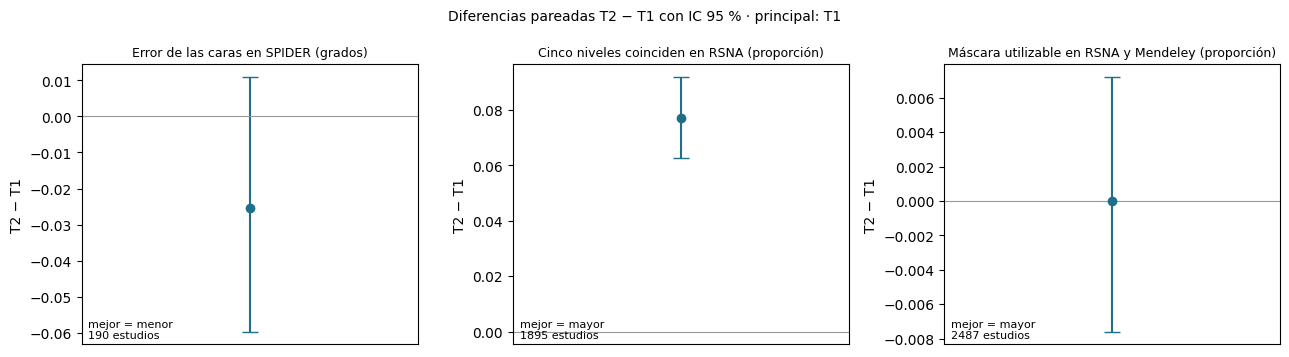

In [11]:
# 10. Comparación pareada T1 frente a T2 y aplicación de la regla
def ic_pareado(dif):
    "Media de las diferencias por estudio e IC 95 % por remuestreo de estudios."
    d = np.asarray(dif, dtype=float)
    d = d[~np.isnan(d)]
    if len(d) < 2:
        return len(d), np.nan, np.nan, np.nan
    rng = np.random.default_rng(SEMILLA)
    medias = [d[rng.integers(0, len(d), len(d))].mean() for _ in range(B_BOOTSTRAP)]
    return len(d), d.mean(), np.percentile(medias, 2.5), np.percentile(medias, 97.5)

def pareados(df, col, estudio="estudio", clase="clase"):
    t = df.pivot_table(index=estudio, columns=clase, values=col, aggfunc="first")
    t = t.dropna(subset=[c for c in ("T1", "T2") if c in t])
    return t["T2"].astype(float) - t["T1"].astype(float)

d1 = pareados(spider_caras, "error_caras_mediana", clase="secuencia")
propias = series_niveles[(series_niveles["clase_puntos"] == series_niveles["clase_mascara"])
                         & (series_niveles["niveles_marcados"] == 5) & series_niveles["con_mascara"]]
d2 = pareados(propias.assign(clase=propias["clase_mascara"], valor=propias["cinco_coinciden"].astype(float)), "valor")
d3 = pareados(marcas_todas.assign(valor=marcas_todas["utilizable"].astype(float))
              .assign(estudio=lambda d: d["conjunto"] + "_" + d["estudio"]), "valor")

medidas = [("Error de las caras en SPIDER (grados)", d1, "menor"),
           ("Cinco niveles coinciden en RSNA (proporción)", d2, "mayor"),
           ("Máscara utilizable en RSNA y Mendeley (proporción)", d3, "mayor")]
filas = []
for nombre, d, mejor_si in medidas:
    n, media, lo, hi = ic_pareado(d)
    t2_mejor = (hi < 0) if mejor_si == "menor" else (lo > 0)
    t2_peor = (lo > 0) if mejor_si == "menor" else (hi < 0)
    filas.append({"medida": nombre, "estudios_pareados": n, "diferencia_T2_menos_T1": round(media, 4),
                  "ic95_inf": round(lo, 4), "ic95_sup": round(hi, 4), "mejor_es": mejor_si,
                  "T2_claramente_mejor": bool(t2_mejor), "T2_claramente_peor": bool(t2_peor)})
comparacion = pd.DataFrame(filas)
n_mejor, n_peor = int(comparacion["T2_claramente_mejor"].sum()), int(comparacion["T2_claramente_peor"].sum())
SECUENCIA_PRINCIPAL = "T2" if (n_mejor >= 2 and n_peor == 0) else "T1"
SECUENCIA_CORROBORACION = "T1" if SECUENCIA_PRINCIPAL == "T2" else "T2"
comparacion.to_csv(DIR_SALIDA / "comparacion_t1_t2.csv", index=False)
decision = {"fecha": datetime.datetime.now().isoformat(timespec="seconds"), "regla_fijada": "2026-10-30",
            "T2_mejor_en": n_mejor, "T2_peor_en": n_peor, "secuencia_principal": SECUENCIA_PRINCIPAL,
            "secuencia_de_corroboracion": SECUENCIA_CORROBORACION}
(DIR_SALIDA / "decision_secuencia.json").write_text(json.dumps(decision, indent=2, ensure_ascii=False), encoding="utf-8")
display(comparacion)
print(f"La T2 es claramente mejor en {n_mejor} y claramente peor en {n_peor} de las tres medidas.")
print(f"Secuencia principal del cuaderno 10: {SECUENCIA_PRINCIPAL} (corroboración: {SECUENCIA_CORROBORACION})")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, (nombre, d, mejor_si), f in zip(axes, medidas, filas):
    ax.errorbar([0], [f["diferencia_T2_menos_T1"]], yerr=[[f["diferencia_T2_menos_T1"] - f["ic95_inf"]],
                [f["ic95_sup"] - f["diferencia_T2_menos_T1"]]], fmt="o", color="#1f6f8b", capsize=6)
    ax.axhline(0, color="#999999", lw=0.8)
    ax.set_xticks([])
    ax.set_title(nombre, fontsize=9)
    ax.set_ylabel("T2 − T1")
    ax.text(0.02, 0.02, f"mejor = {mejor_si}\n{f['estudios_pareados']} estudios", transform=ax.transAxes, fontsize=8)
fig.suptitle(f"Diferencias pareadas T2 − T1 con IC 95 % · principal: {SECUENCIA_PRINCIPAL}", fontsize=10)
plt.tight_layout()
fig.savefig(DIR_SALIDA / "comparacion_t1_t2.png", dpi=120, bbox_inches="tight", facecolor="white")
plt.show()

**Cómo leer la salida de la celda 10.** Cada fila corresponde a una de las tres medidas y presenta la diferencia media T2 menos T1 entre estudios pareados, junto con su intervalo de confianza. En el error de las caras, un valor negativo favorece a T2 porque representa un error menor. En las otras dos medidas, un valor positivo favorece a T2 porque indica una mayor coincidencia o una mayor proporción de máscaras utilizables. Las dos últimas columnas indican si el intervalo permite concluir que T2 es claramente mejor o claramente peor. Debajo de la tabla aparece la decisión final. En la gráfica, cada punto representa la diferencia media y su intervalo de confianza. La línea gris indica la igualdad entre secuencias.

**Resultados.** La T2 resulta claramente mejor en una sola de las tres medidas: la coincidencia de los niveles con la numeración de RSNA, cuya diferencia es de 0,077, con un IC del 95 % entre 0,063 y 0,092. En las otras dos medidas no se observa una diferencia estadísticamente clara entre secuencias. Para el error de las caras en SPIDER, la diferencia es de −0,025°, con un IC del 95 % entre −0,060° y 0,011°. Para la proporción de máscaras utilizables, la diferencia es 0,000, con un IC del 95 % entre −0,008 y 0,007.

Como la regla exige que T2 sea mejor en al menos dos medidas, la T1 queda definida como secuencia principal del cuaderno 10. La T2 se analizará completa como corroboración. Además, los resultados de la celda 8 sugieren que la ventaja de T2 en la coincidencia con RSNA está relacionada principalmente con el tipo de punto que se marca en cada secuencia, más que con una diferencia importante entre las máscaras.

## Comprobaciones antes del cuaderno 10

Estas comprobaciones no forman parte de la regla utilizada para elegir la secuencia principal. Sin embargo, sus resultados se incorporan al plan de análisis porque permiten valorar la numeración de los discos y la cobertura de las series antes de calcular cualquier ángulo.

La celda 11 compara la numeración de la T1 y la T2 del mismo estudio. Ambas series se adquieren durante la misma sesión y comparten el sistema de coordenadas del equipo, por lo que un mismo disco debería conservar prácticamente la misma posición en las dos máscaras. Cada disco de T2 se empareja con el disco T1 más cercano. La pareja debe ser mutua y estar a menos de 15 mm, una distancia inferior a la mitad de la separación habitual entre discos. Después se comprueba si TotalSpineSeg asignó el mismo nombre a ambos.

Esta comparación es especialmente útil en Mendeley, donde no hay puntos de referencia para comprobar la numeración. En RSNA, además, permite hacer una comprobación independiente de las anotaciones. La distancia entre los centros de los discos emparejados también sirve para estimar cuánto se desplazó el paciente entre las dos adquisiciones.

La celda 12 identifica las máscaras que contienen una sexta vértebra lumbar, etiqueta 46 de TotalSpineSeg, y el disco L5-L6, etiqueta 96. La presencia de una vértebra de transición puede cambiar qué disco se identifica como L5-S1 y explicar parte de las discrepancias con RSNA. Por eso también se compara la coincidencia de la celda 8 entre las máscaras con L6 y aquellas que no la tienen.

La celda 13 describe la adquisición de las series de RSNA. Incluye el número de cortes, el tamaño del píxel, el paso entre cortes, la cobertura lateral y el campo de visión. También compara las series con y sin máscara y cuenta las combinaciones de parámetros de adquisición, denominadas huellas de protocolo. Estas huellas se utilizan porque las cabeceras no contienen información suficiente sobre la institución y el equipo. Sin embargo, una huella de protocolo no equivale a una institución: distintos centros pueden utilizar el mismo protocolo y un mismo centro puede utilizar varios.

Por último, la celda 14 compara la cobertura lateral de cada serie, calculada a partir del número de cortes y el paso entre ellos, con el ancho de los discos lumbares. El objetivo es comprobar si los discos que tocan el borde lateral aparecen principalmente en adquisiciones con una cobertura demasiado estrecha.

In [12]:
# 11. ¿Numeran igual la T1 y la T2 del mismo estudio?
def corrimiento_dominante(valores):
    "0 si todas las parejas tienen el mismo nombre; si no, el corrimiento distinto de 0 más frecuente."
    distintos = [v for v in valores if v != 0 and not np.isnan(v)]
    return 0 if not distintos else int(pd.Series(distintos).mode().iloc[0])

pares_t1_t2 = (listas[listas["id_serie"].isin(set(ids_ok))]
               .pivot_table(index=["conjunto", "estudio"], columns="clase", values="id_serie", aggfunc="first")
               .dropna(subset=["T1", "T2"]))
filas = []
for (conjunto, estudio), r in pares_t1_t2.iterrows():
    d1, d2 = discos_de.get(r["T1"]), discos_de.get(r["T2"])
    if d1 is None or d2 is None or d1.empty or d2.empty:
        continue
    P1, P2 = d1[["x_mm", "y_mm", "z_mm"]].to_numpy(), d2[["x_mm", "y_mm", "z_mm"]].to_numpy()
    e1, e2 = d1["etiqueta"].to_numpy(), d2["etiqueta"].to_numpy()
    D = np.linalg.norm(P2[:, None, :] - P1[None, :, :], axis=2)
    parejas = [(i, int(D[i].argmin())) for i in range(len(P2))
               if D[i].min() < MAX_PAREJA_T1_T2_MM and int(D[:, D[i].argmin()].argmin()) == i]
    lumbares = [(i, j) for i, j in parejas if e1[j] in DISCOS_LUMBARES or e2[i] in DISCOS_LUMBARES]
    filas.append({"conjunto": conjunto, "estudio": estudio, "discos_t1": len(P1), "discos_t2": len(P2),
                  "parejas": len(parejas), "parejas_lumbares": len(lumbares),
                  "lumbares_mismo_nombre": int(sum(e1[j] == e2[i] for i, j in lumbares)),
                  "corrimiento_t2_menos_t1": corrimiento_dominante(
                      [ORDEN_DISCO.get(int(e2[i]), np.nan) - ORDEN_DISCO.get(int(e1[j]), np.nan) for i, j in lumbares]),
                  "distancia_mediana_mm": float(np.median([D[i, j] for i, j in parejas])) if parejas else np.nan})
num_t1_t2 = pd.DataFrame(filas)
num_t1_t2["misma_numeracion"] = ((num_t1_t2["parejas_lumbares"] > 0)
                                 & (num_t1_t2["lumbares_mismo_nombre"] == num_t1_t2["parejas_lumbares"]))
num_t1_t2.to_csv(DIR_PRIV / "numeracion_t1_t2_por_estudio.csv", index=False)
num_t1_t2[num_t1_t2["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "numeracion_t1_t2_mendeley.csv", index=False)
resumen_num = num_t1_t2.groupby("conjunto").agg(
    estudios=("estudio", "size"),
    sin_parejas_lumbares_pct=("parejas_lumbares", lambda x: round(100 * (x == 0).mean(), 1)),
    misma_numeracion_pct=("misma_numeracion", lambda x: round(100 * x.mean(), 1)),
    distancia_mediana_mm=("distancia_mediana_mm", "median"),
    distancia_p90_mm=("distancia_mediana_mm", lambda x: x.quantile(0.9)))
resumen_num.round(2).to_csv(DIR_SALIDA / "numeracion_t1_t2_resumen.csv")
corr_t1_t2 = (num_t1_t2[num_t1_t2["parejas_lumbares"] > 0].groupby("conjunto")["corrimiento_t2_menos_t1"]
              .value_counts().unstack(fill_value=0))
corr_t1_t2.to_csv(DIR_SALIDA / "numeracion_t1_t2_corrimientos.csv")
print("Numeración de los discos lumbares en la T1 y la T2 del mismo estudio:")
display(resumen_num.round(2))
print("Estudios según cuántos niveles se corre la numeración de la T2 respecto de la T1 (0 = igual):")
display(corr_t1_t2)

Numeración de los discos lumbares en la T1 y la T2 del mismo estudio:


,estudios,sin_parejas_lumbares_pct,misma_numeracion_pct,distancia_mediana_mm,distancia_p90_mm
conjunto,,,,,
mendeley,510,0.2,99.2,0.65,1.47
rsna,1971,0.2,98.7,1.07,2.87


Estudios según cuántos niveles se corre la numeración de la T2 respecto de la T1 (0 = igual):


corrimiento_t2_menos_t1,-18,-2,-1,0,1,4
conjunto,,,,,,
mendeley,1,0,1,506,0,1
rsna,0,2,7,1946,12,0


**Cómo leer la salida de la celda 11.** `misma_numeracion_pct` indica el porcentaje de estudios en los que todos los discos lumbares emparejados reciben el mismo nombre en T1 y T2. `sin_parejas_lumbares_pct` representa los estudios en los que no fue posible emparejar ningún disco lumbar, por ejemplo, porque el desplazamiento entre las dos series superó los 15 mm. La distancia entre parejas corresponde a la separación entre sus centros. Si el paciente se mantuvo quieto, se espera que esta distancia sea pequeña. La segunda tabla muestra cuántos niveles se desplazó la numeración de T2 respecto a T1 en los estudios donde no coincidió.

**Resultados.** La T1 y la T2 del mismo estudio asignaron la misma numeración a los discos lumbares en el 99,2 % de los estudios de Mendeley y el 98,7 % de los de RSNA. En solo el 0,2 % de cada conjunto no fue posible emparejar ningún disco lumbar. La distancia entre los centros de un mismo disco fue de 0,65 mm en Mendeley y 1,07 mm en RSNA, como mediana. El percentil 90 fue de 1,47 mm y 2,87 mm, respectivamente. Estas distancias pequeñas respaldan la comparación directa de las dos máscaras de cada estudio en el cuaderno 10.

En RSNA, 21 estudios presentaron alguna diferencia de numeración y en 19 de ellos el desplazamiento fue de un solo nivel. En Mendeley se identificaron tres casos. Uno corresponde al estudio 0245, cuya T2 es cervical mientras que la T1 es lumbar. Los otros dos presentan desplazamientos de uno y cuatro niveles.

In [13]:
# 12. Sexta vértebra lumbar (etiqueta 46) y disco L5-L6 (96)
presentes = etiquetas.groupby("id_serie")["etiqueta"].agg(set)
trans = datos_lista.loc[datos_lista.index.isin(presentes.index), ["conjunto", "estudio", "clase"]].copy()
trans["con_L6"] = [46 in presentes[i] for i in trans.index]
trans["con_disco_L5_L6"] = [96 in presentes[i] for i in trans.index]
trans["sin_L5"] = [45 not in presentes[i] for i in trans.index]
resumen_l6 = trans.groupby(["conjunto", "clase"]).agg(
    mascaras=("con_L6", "size"), con_L6_pct=("con_L6", lambda x: round(100 * x.mean(), 1)),
    con_disco_L5_L6_pct=("con_disco_L5_L6", lambda x: round(100 * x.mean(), 1)),
    sin_L5_pct=("sin_L5", lambda x: round(100 * x.mean(), 1)))
pv = trans.reset_index().pivot_table(index=["conjunto", "estudio"], columns="clase", values="con_L6", aggfunc="first")
pv = pv.dropna(subset=["T1", "T2"]).astype(bool)
concordancia_l6 = pv.groupby(level="conjunto").apply(lambda g: pd.Series({
    "estudios": len(g), "L6_en_las_dos": int((g["T1"] & g["T2"]).sum()), "L6_solo_en_una": int((g["T1"] ^ g["T2"]).sum())}))
if len(series_niveles):
    sn = series_niveles[(series_niveles["clase_puntos"] == series_niveles["clase_mascara"])
                        & (series_niveles["niveles_marcados"] == 5) & series_niveles["con_mascara"]].copy()
    sn["con_L6"] = [bool(trans["con_L6"].get(mascara_de.get((e, c)), False)) for e, c in zip(sn["estudio"], sn["clase_mascara"])]
    niveles_por_l6 = sn.groupby(["clase_mascara", "con_L6"]).agg(
        estudios=("estudio", "size"), pct_cinco_coinciden=("cinco_coinciden", lambda x: round(100 * x.mean(), 1)))
else:
    niveles_por_l6 = pd.DataFrame()
resumen_l6.to_csv(DIR_SALIDA / "sexta_lumbar_resumen.csv")
concordancia_l6.to_csv(DIR_SALIDA / "sexta_lumbar_t1_t2.csv")
niveles_por_l6.to_csv(DIR_SALIDA / "niveles_rsna_segun_sexta_lumbar.csv")
print("Máscaras con sexta lumbar, con disco L5-L6 y sin L5:")
display(resumen_l6)
print("¿Aparece la sexta lumbar en las dos series del estudio?")
display(concordancia_l6)
print("Coincidencia de los cinco niveles con RSNA, según si la máscara trae sexta lumbar:")
display(niveles_por_l6)

Máscaras con sexta lumbar, con disco L5-L6 y sin L5:


mascaras  con_L6_pct  con_disco_L5_L6_pct  sin_L5_pct
conjunto clase                                                       
mendeley T1          515         0.4                  0.4         0.0
         T2          510         0.2                  0.2         0.2
rsna     T1         1972         0.5                  0.5         0.0
         T2         1974         0.3                  0.3         0.1

¿Aparece la sexta lumbar en las dos series del estudio?


,estudios,L6_en_las_dos,L6_solo_en_una
conjunto,,,
mendeley,510,1,1
rsna,1971,2,10


Coincidencia de los cinco niveles con RSNA, según si la máscara trae sexta lumbar:


estudios  pct_cinco_coinciden
clase_mascara con_L6                               
T1            False       1962                 89.4
              True           9                  0.0
T2            False       1893                 97.4
              True           5                  0.0

**Cómo leer la salida de la celda 12.** La primera tabla muestra el porcentaje de máscaras que contienen la etiqueta L6, el disco L5-L6 y aquellas en las que falta L5. La segunda indica en cuántos estudios la sexta vértebra lumbar aparece en ambas secuencias y en cuántos aparece solamente en una. Este último caso representa una inconsistencia de segmentación, porque la anatomía del paciente es la misma en las dos adquisiciones. La tercera tabla compara la coincidencia de los cinco niveles con RSNA según la presencia o ausencia de L6. Cuando existe una sexta vértebra lumbar, el disco que RSNA identifica como L5-S1 podría corresponder al L5-L6 o al L6-S de TotalSpineSeg, etiqueta 100. Por eso se espera una menor coincidencia.

**Resultados.** TotalSpineSeg identificó una sexta vértebra lumbar en muy pocas máscaras, con porcentajes entre 0,2 % y 0,5 %, según el conjunto y la secuencia. En RSNA, L6 aparece en ambas secuencias de solo dos estudios y en una sola secuencia de otros diez. En Mendeley aparece en ambas secuencias de un estudio y en una sola secuencia de otro. Esto muestra que, cuando el modelo identifica una sexta vértebra lumbar, no siempre lo hace de manera consistente entre T1 y T2.

Ninguna de las máscaras que contienen L6 coincide con RSNA en los cinco niveles. Esto ocurre en nueve estudios T1 y cinco estudios T2. En las máscaras sin L6, en cambio, la coincidencia alcanza el 89,4 % en T1 y el 97,4 % en T2. El resultado es compatible con el problema de numeración esperado: cuando existe una sexta vértebra lumbar, el disco que RSNA llama L5-S1 puede corresponder a L5-L6 o L6-S según la convención utilizada. Por este motivo, la presencia de L6 se conserva como una marca de calidad en el cuaderno 10.

In [14]:
# 13. Adquisición de las series de RSNA, series sin máscara y huellas de protocolo
reg_rsna = registro[registro["conjunto"] == "rsna"]
adq = geometria.set_index("id_serie").join(datos_lista[["clase"]], how="left")
adq["fallo"] = reg_rsna["estado"].reindex(adq.index) != "ok"
adq["cobertura_lr_mm"] = adq["paso_cortes"] * adq["cortes"]
adq["campo_mayor_mm"] = np.maximum(adq["filas"] * adq["espaciado_j"], adq["columnas"] * adq["espaciado_i"])
VARIABLES = ["cortes", "espaciado_i", "paso_cortes", "cobertura_lr_mm", "campo_mayor_mm"]
sin_conversion = int((reg_rsna["error"].fillna("").str.startswith("error de entrada")).sum())
print(f"RSNA: {int(adq['fallo'].sum())} series sin máscara de {len(adq)} convertidas "
      f"({adq['fallo'].mean():.1%}); además {sin_conversion} que no se pudieron convertir")
medianas = adq.groupby(["clase", "fallo"])[VARIABLES].median().round(2)
medianas["series"] = adq.groupby(["clase", "fallo"]).size()
medianas.to_csv(DIR_SALIDA / "fallos_rsna_medianas.csv")
display(medianas)
filas = []
for v in VARIABLES:
    tramos = pd.qcut(adq[v], 4, duplicates="drop")
    for tramo, g in adq.groupby(tramos, observed=True):
        filas.append({"variable": v, "tramo": str(tramo), "series": len(g), "fallo_pct": round(100 * g["fallo"].mean(), 1)})
fallos_por_tramo = pd.DataFrame(filas)
fallos_por_tramo.to_csv(DIR_SALIDA / "fallos_rsna_por_cuartil.csv", index=False)
print("Porcentaje de series sin máscara por cuartil de cada variable de adquisición:")
display(fallos_por_tramo.pivot_table(index=["variable", "tramo"], values=["series", "fallo_pct"], aggfunc="first", sort=False))

# Huellas de protocolo: combinaciones de parámetros de adquisición (sin identificar instituciones)
adq["huella_protocolo"] = (adq["cortes"].astype(int).astype(str) + "|" + adq["filas"].astype(str) + "x" + adq["columnas"].astype(str)
                           + "|" + adq["espaciado_i"].round(3).astype(str) + "|" + adq["paso_cortes"].round(2).astype(str))
filas = []
for clase, g in adq.groupby("clase"):
    frec = g["huella_protocolo"].value_counts()
    filas.append({"clase": clase, "series": len(g), "huellas_distintas": len(frec),
                  "huellas_con_10_o_mas_series": int((frec >= 10).sum()),
                  "series_en_las_10_mas_frecuentes_pct": round(100 * frec.head(10).sum() / len(g), 1),
                  "series_en_huellas_unicas_pct": round(100 * (frec == 1).sum() / len(g), 1)})
huellas_protocolo = pd.DataFrame(filas)
# Huella gruesa: solo la matriz de la imagen y el paso entre cortes redondeado a 0,5 mm (el tamaño del píxel y el número
# de cortes cambian de un paciente a otro con el campo de visión, así que separan series de un mismo protocolo)
adq["huella_gruesa"] = (adq["filas"].astype(str) + "x" + adq["columnas"].astype(str) + "|" + (adq["paso_cortes"] * 2).round().div(2).astype(str))
for k, (clase, g) in enumerate(adq.groupby("clase")):
    frec = g["huella_gruesa"].value_counts()
    huellas_protocolo.loc[k, "huellas_gruesas_distintas"] = len(frec)
    huellas_protocolo.loc[k, "huellas_gruesas_con_10_o_mas_series"] = int((frec >= 10).sum())
    huellas_protocolo.loc[k, "series_en_huellas_gruesas_con_10_o_mas_pct"] = round(100 * frec[frec >= 10].sum() / len(g), 1)
huellas_protocolo.to_csv(DIR_SALIDA / "rsna_huellas_protocolo_resumen.csv", index=False)
adq[["huella_protocolo", "huella_gruesa"]].to_csv(DIR_PRIV / "rsna_huella_protocolo_por_serie.csv")
print("Huellas de protocolo en RSNA (fina: cortes, matriz, píxel y paso; gruesa: matriz y paso redondeado a 0,5 mm):")
display(huellas_protocolo)

RSNA: 0 series sin máscara de 3946 convertidas (0.0%); además 1 que no se pudieron convertir


,,cortes,espaciado_i,paso_cortes,cobertura_lr_mm,campo_mayor_mm,series
clase,fallo,,,,,,
T1,False,17.0,0.68,4.48,75.0,299.98,1972
T2,False,17.0,0.58,4.48,75.0,280.00,1974


Porcentaje de series sin máscara por cuartil de cada variable de adquisición:


series  fallo_pct
variable        tramo                                
cortes          (7.999, 15.0]         1556        0.0
                (15.0, 17.0]           750        0.0
                (17.0, 19.0]           931        0.0
                (19.0, 29.0]           709        0.0
espaciado_i     (0.272, 0.536]        1068        0.0
                (0.536, 0.647]         905        0.0
                (0.647, 0.781]        1023        0.0
                (0.781, 1.176]         950        0.0
paso_cortes     (2.999, 4.4]           987        0.0
                (4.4, 4.48]            986        0.0
                (4.48, 4.8]            986        0.0
                (4.8, 6.6]             987        0.0
cobertura_lr_mm (47.999, 69.0]         987        0.0
                (69.0, 75.0]           986        0.0
                (75.0, 80.64]          986        0.0
                (80.64, 135.0]         987        0.0
campo_mayor_mm  (199.986, 267.188]     989        0.0
                (267.188, 280.013]    1154        0.0
                (280.013, 300.0]       873        0.0
                (300.0, 521.094]       930        0.0

Huellas de protocolo en RSNA (fina: cortes, matriz, píxel y paso; gruesa: matriz y paso redondeado a 0,5 mm):


,clase,series,huellas_distintas,huellas_con_10_o_mas_series,series_en_las_10_mas_frecuentes_pct,series_en_huellas_unicas_pct,huellas_gruesas_distintas,huellas_gruesas_con_10_o_mas_series,series_en_huellas_gruesas_con_10_o_mas_pct
0,T1,1972,503,38,30.0,15.2,90.0,21.0,92.6
1,T2,1974,550,43,24.6,16.8,102.0,30.0,93.2


**Cómo leer la salida de la celda 13.** La primera tabla presenta las medianas de las variables de adquisición para las series con máscara y sin ella, separadas por secuencia. La segunda divide cada variable en cuartiles y muestra el porcentaje de series sin máscara en cada grupo. Si los fallos se concentran en un intervalo, por ejemplo, en las series con menos cortes, la muestra que llega al cuaderno 10 podría representar de manera desigual los protocolos de RSNA. Las variables se obtienen de las cabeceras DICOM. La cobertura lateral se calcula multiplicando el número de cortes por el paso entre ellos.

La última tabla resume las huellas de protocolo. Primero se utiliza una definición fina, que combina número de cortes, matriz, tamaño del píxel y paso entre cortes. Después se utiliza una definición más general, que considera la matriz y el paso entre cortes redondeado a 0,5 mm. Esta segunda definición es la que se empleará en el cuaderno 10, porque el número de cortes y el tamaño del píxel pueden variar entre pacientes que utilizan un mismo protocolo.

**Resultados.** TotalSpineSeg no presentó fallos de segmentación en ninguna de las 3.946 series de RSNA que pudieron convertirse. Además, hubo una serie que no se pudo convertir. Por tanto, no se observa un patrón de fallos de segmentación asociado con las características de adquisición. La tabla se interpreta principalmente como una descripción de los protocolos disponibles.

Las series tienen una mediana de 17 cortes, con un paso entre cortes de 4,48 mm y una cobertura lateral de 75 mm. El tamaño de píxel mediano es de 0,68 mm en T1 y 0,58 mm en T2, mientras que el campo de visión se sitúa aproximadamente entre 280 y 300 mm.

Con la huella fina se identifican 503 combinaciones distintas en las 1.972 series T1 y 550 en las 1.974 series T2. Solo 38 y 43 combinaciones, respectivamente, reúnen diez series o más. Las diez huellas más frecuentes agrupan el 30,0 % de las series T1 y el 24,6 % de las T2. Además, el 15,2 % y el 16,8 % de las series tienen una combinación que aparece una sola vez. Esta definición es demasiado específica y separa adquisiciones que probablemente proceden de un mismo protocolo.

Con la huella más general, el número de combinaciones baja a 90 en T1 y 102 en T2. Las combinaciones que reúnen diez series o más agrupan el 92,6 % de las series T1 y el 93,2 % de las T2. Esta definición ofrece una descripción más útil de los protocolos y es la que se utilizará en el cuaderno 10.

In [15]:
# 14. Cobertura lateral del campo frente al ancho de los discos lumbares
rr = reg_rec[reg_rec["estado"] == "ok"].set_index("id_serie")
rr["cobertura_lr_mm"] = rr["cortes_lr"] * rr["esp_lr"]
lum = etiquetas[etiquetas["etiqueta"].isin(DISCOS_LUMBARES)].copy()
lum["ancho_lr_mm"] = lum["cortes_lr_con_etiqueta"] * lum["id_serie"].map(rr["esp_lr"])
por_mascara = lum.groupby("id_serie").agg(ancho_disco_max_mm=("ancho_lr_mm", "max"),
                                          disco_toca_lateral=("toca_borde_lateral", "any"))
cob = rr[["cobertura_lr_mm"]].join(por_mascara, how="inner").join(datos_lista[["conjunto", "clase"]])
cob["tramo_cobertura_mm"] = pd.cut(cob["cobertura_lr_mm"], [0, 50, 60, 70, 80, 90, 10000], right=False,
                                   labels=["<50", "50–60", "60–70", "70–80", "80–90", "≥90"])
resumen_cob = cob.groupby(["conjunto", "tramo_cobertura_mm"], observed=True).agg(
    mascaras=("cobertura_lr_mm", "size"), ancho_disco_mediana_mm=("ancho_disco_max_mm", "median"),
    disco_toca_lateral_pct=("disco_toca_lateral", lambda x: round(100 * x.mean(), 1)))
resumen_cob.round(1).to_csv(DIR_SALIDA / "cobertura_lateral_resumen.csv")
print("Medianas por conjunto y secuencia (mm):")
display(cob.groupby(["conjunto", "clase"])[["cobertura_lr_mm", "ancho_disco_max_mm"]].median().round(1))
print("Discos lumbares que tocan el borde lateral, por cobertura lateral de la serie:")
display(resumen_cob.round(1))

Medianas por conjunto y secuencia (mm):


cobertura_lr_mm  ancho_disco_max_mm
conjunto clase                                     
mendeley T1                72.0                52.8
         T2                72.0                52.8
rsna     T1                75.0                52.8
         T2                75.0                51.6

Discos lumbares que tocan el borde lateral, por cobertura lateral de la serie:


mascaras  ancho_disco_mediana_mm  \
conjunto tramo_cobertura_mm                                     
mendeley 50–60                      4                    48.0   
         60–70                     73                    50.8   
         70–80                    944                    52.8   
         80–90                      1                    59.4   
         ≥90                        2                    48.8   
rsna     <50                       11                    46.2   
         50–60                    132                    49.5   
         60–70                    914                    50.6   
         70–80                   1445                    52.0   
         80–90                   1127                    53.8   
         ≥90                      316                    55.0   

                             disco_toca_lateral_pct  
conjunto tramo_cobertura_mm                          
mendeley 50–60                                100.0  
         60–70                                  6.8  
         70–80                                  3.7  
         80–90                                100.0  
         ≥90                                    0.0  
rsna     <50                                  100.0  
         50–60                                 50.0  
         60–70                                 24.2  
         70–80                                  4.8  
         80–90                                  0.5  
         ≥90                                    1.9

**Cómo leer la salida de la celda 14.** La cobertura lateral se calcula multiplicando el número de cortes por el paso entre ellos. El ancho del disco corresponde al número de cortes en los que aparece el disco lumbar más ancho de la máscara, multiplicado por ese mismo paso. De esta manera, ambas medidas se expresan en milímetros y pueden compararse directamente. Si la proporción de discos que tocan el borde disminuye cuando aumenta la cobertura, es probable que los discos cortados se deban a adquisiciones demasiado estrechas y no a un error del segmentador.

**Resultados.** La cobertura lateral mediana es de 72 mm en Mendeley y 75 mm en RSNA. El disco lumbar más ancho mide aproximadamente 52 mm en ambos conjuntos. En RSNA se observa una relación clara entre la cobertura y los discos que tocan el borde lateral. Esto ocurre en todas las series con menos de 50 mm de cobertura, en el 50,0 % de las series entre 50 y 60 mm, en el 24,2 % de las que tienen entre 60 y 70 mm y en el 4,8 % de las que se encuentran entre 70 y 80 mm. Para coberturas entre 80 y 90 mm, el porcentaje baja al 0,5 %, mientras que en las series de 90 mm o más es del 1,9 %.

Mendeley muestra el mismo comportamiento en los intervalos con más observaciones. Los discos tocan el borde en el 6,8 % de las series con cobertura entre 60 y 70 mm y en el 3,7 % de las que tienen entre 70 y 80 mm. Los grupos de cobertura más extrema contienen muy pocas series, por lo que sus porcentajes deben interpretarse con cautela. En conjunto, los resultados respaldan que los discos cortados se relacionan principalmente con una cobertura lateral insuficiente.

## Muestra para el cuaderno 10

La celda 15 calcula cuántos estudios cuentan con las dos secuencias utilizables y, por tanto, pueden entrar en la comparación entre T1 y T2. También identifica cuántos de esos estudios tienen la misma numeración en ambas máscaras.

Con el número de estudios disponibles se estima la precisión esperada de los límites de acuerdo. Según Bland y Altman, el error estándar de un límite de acuerdo es aproximadamente √(3/n) veces la desviación estándar de las diferencias. Por tanto, la semiamplitud de su intervalo de confianza del 95 % se estima como 1,96 · √(3/n) desviaciones estándar.

En Mendeley también se describe el sexo y la edad de los estudios que llegan a esta etapa. Estos datos proceden de las cabeceras DICOM recuperadas en el cuaderno 08 y son necesarios porque el plan contempla informar la proporción de ángulos de 10° o más por sexo y por grupos de edad.

In [16]:
# 15. Muestra disponible para el cuaderno 10
util = marcas_todas.reset_index().pivot_table(index=["conjunto", "estudio"], columns="clase", values="utilizable",
                                               aggfunc="first").fillna(False).astype(bool)
misma = num_t1_t2.set_index(["conjunto", "estudio"])["misma_numeracion"].reindex(util.index).fillna(False).astype(bool)
muestra = pd.DataFrame({"T1_utilizable": util["T1"], "T2_utilizable": util["T2"]})
muestra["las_dos"] = muestra["T1_utilizable"] & muestra["T2_utilizable"]
muestra["las_dos_y_misma_numeracion"] = muestra["las_dos"] & misma
resumen_muestra = muestra.groupby(level="conjunto").agg(
    estudios=("las_dos", "size"), con_T1_utilizable=("T1_utilizable", "sum"), con_T2_utilizable=("T2_utilizable", "sum"),
    con_las_dos=("las_dos", "sum"), con_las_dos_y_misma_numeracion=("las_dos_y_misma_numeracion", "sum"))
resumen_muestra["semiamplitud_ic_limite_acuerdo_en_DE"] = (1.96 * np.sqrt(3 / resumen_muestra["con_las_dos"])).round(3)
resumen_muestra.to_csv(DIR_SALIDA / "muestra_cuaderno_10.csv")
print("Estudios que llegan al cuaderno 10:")
display(resumen_muestra)

# Mendeley: sexo y edad de los estudios con las dos series utilizables (solo agregados)
series_m = pd.read_csv(CSV_SERIES_MENDELEY_08, dtype={"paciente": str, "sexo": str, "edad": str})
paciente = series_m.groupby("paciente")[["sexo", "edad"]].first()
paciente["edad_anios"] = pd.to_numeric(paciente["edad"].str.extract(r"(\d+)")[0], errors="coerce")
est_men = [e for (c, e) in muestra.index[muestra["las_dos"]] if c == "mendeley"]
demo = paciente.reindex(est_men)
demo["grupo_edad"] = pd.cut(demo["edad_anios"], [0, 40, 60, 200], right=False, labels=["<40", "40–59", "≥60"])
tabla_demo = (demo.assign(sexo=demo["sexo"].fillna("sin dato"), grupo_edad=demo["grupo_edad"].cat.add_categories("sin dato").fillna("sin dato"))
              .groupby(["sexo", "grupo_edad"], observed=True).size().unstack(fill_value=0))
tabla_demo.to_csv(DIR_SALIDA / "mendeley_sexo_edad_muestra.csv")
print(f"Mendeley, estudios con las dos series utilizables: {len(est_men)} | edad mediana {demo['edad_anios'].median():.0f} años "
      f"(p10 {demo['edad_anios'].quantile(0.1):.0f}, p90 {demo['edad_anios'].quantile(0.9):.0f})")
display(tabla_demo)

/tmp/ipykernel_5233/2937106614.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  aggfunc="first").fillna(False).astype(bool)
/tmp/ipykernel_5233/2937106614.py:4: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  misma = num_t1_t2.set_index(["conjunto", "estudio"])["misma_numeracion"].reindex(util.index).fillna(False).astype(bool)


Estudios que llegan al cuaderno 10:


,estudios,con_T1_utilizable,con_T2_utilizable,con_las_dos,con_las_dos_y_misma_numeracion,semiamplitud_ic_limite_acuerdo_en_DE
conjunto,,,,,,
mendeley,515,491,485,478,477,0.155
rsna,1975,1774,1780,1738,1731,0.081


Mendeley, estudios con las dos series utilizables: 478 | edad mediana 40 años (p10 26, p90 58)


grupo_edad,<40,40–59,≥60
sexo,,,
F,81,83,22
M,154,115,23


**Cómo leer la salida de la celda 15.** La primera tabla muestra, para cada conjunto, cuántos estudios tienen una T1 utilizable, una T2 utilizable o ambas. También indica cuántos de los estudios con las dos secuencias tienen la misma numeración en ambas máscaras. La última columna expresa la semiamplitud del intervalo de confianza del 95 % de cada límite de acuerdo, en unidades de la desviación estándar de las diferencias entre T1 y T2. Por ejemplo, si esa desviación fuera de 2° y la semiamplitud fuera de 0,1, cada límite se estimaría con un margen aproximado de ±0,2°. La segunda tabla describe el sexo y los grupos de edad de los estudios de Mendeley que llegan al análisis.

**Resultados.** Según la salida de la celda, 478 estudios de Mendeley y 1.738 de RSNA cuentan con las dos secuencias utilizables. De ellos, 477 y 1.731, respectivamente, tienen además la misma numeración en ambas máscaras. Con estos tamaños, la semiamplitud del intervalo de confianza del 95 % de cada límite de acuerdo se estima en 0,155 desviaciones estándar en Mendeley y 0,081 en RSNA. Si la desviación estándar de las diferencias fuera de 2°, esto equivaldría a márgenes aproximados de ±0,31° y ±0,16°.

Los 478 estudios de Mendeley están distribuidos entre 186 mujeres y 292 hombres. La edad mediana es de 40 años, con percentiles 10 y 90 de 26 y 58 años. Por grupos de edad, 235 estudios corresponden a menores de 40 años, 198 al grupo de 40 a 59 años y 45 a personas de 60 años o más. Este último grupo es pequeño, con 22 mujeres y 23 hombres, por lo que las proporciones por edad tendrán menor precisión en ese segmento.

## Plan de análisis para OSF

La celda 16 muestra el plan de análisis del cuaderno 10, guardado en `plan_analisis_cuaderno_10.md` dentro de la carpeta de resultados, y calcula su huella SHA-256. El plan se generó con los números de esta ejecución e incorpora la secuencia principal elegida mediante la regla definida previamente.

El plan se registró en OSF el 31 de octubre de 2026, antes de calcular cualquier ángulo coronal de RSNA o Mendeley: doi:[10.17605/OSF.IO/KP5DU](https://doi.org/10.17605/OSF.IO/KP5DU). El registro adjunta este mismo archivo, y su huella SHA-256 permite comprobar que el plan registrado es exactamente el que está en la carpeta de resultados.

In [17]:
# Plan de análisis del cuaderno 10: se generó con esta corrida y se registró en OSF; aquí solo se lee y se comprueba su huella
ruta_plan = DIR_SALIDA / "plan_analisis_cuaderno_10.md"
plan = ruta_plan.read_text(encoding="utf-8")
huella_plan = hashlib.sha256(plan.encode("utf-8")).hexdigest()
(DIR_SALIDA / "plan_analisis_cuaderno_10.sha256").write_text(f"{huella_plan}  plan_analisis_cuaderno_10.md\n", encoding="utf-8")
print(plan)
print("SHA-256 del plan:", huella_plan)

# Plan de análisis del cuaderno 10: ángulo coronal lumbar en RSNA y Mendeley

Proyecto de investigación sobre la medición del ángulo coronal lumbar en RM sagital (repositorio FabianND/cobb-rm-lumbar). Este plan se generó en el cuaderno 09 el 2026-10-31, antes de calcular ningún ángulo coronal en RSNA o en Mendeley.

## 1. Pregunta y alcance
El objetivo es estudiar las propiedades de medición de un ángulo coronal lumbar calculado automáticamente a partir de
RM sagital de rutina en adultos, utilizando dos conjuntos externos, RSNA LumbarDISC y Lumbar Spine MRI Dataset de
Mendeley. La variable se denomina "ángulo coronal lumbar en decúbito estimado en RM sagital". No corresponde al
ángulo de Cobb clínico, que se mide en radiografías de pie. Ninguno de los dos conjuntos dispone de un ángulo de
referencia. Por tanto, este trabajo no evalúa exactitud diagnóstica, no estima una probabilidad de escoliosis y tampoco
entrena un modelo.

## 2. Datos
Se utilizarán las máscaras de TotalSpineSeg (paq

**Cómo leer la salida de la celda 16.** La salida muestra el plan de análisis completo, con la secuencia principal y los números de esta ejecución, seguido de su huella SHA-256. Esa huella debe coincidir con la que quedó registrada en OSF; si no coincide, el archivo de la carpeta de resultados no es el que se registró.

In [18]:
# 17. LEEME.md de la carpeta de resultados
leeme = f"""# 09 · Segmentación externa: revisión técnica y plan de análisis

Resultados de `notebooks/09_segmentacion_externa.ipynb`. Solo investigación; no es para diagnóstico.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos: aquí solo hay resúmenes
agregados de RSNA. Las tablas por estudio, serie o punto, las máscaras y su traducción están en carpetas privadas.
Mendeley (doi:10.17632/k57fr854j2.2) y SPIDER tienen licencia CC BY 4.0.

| Archivo | Qué contiene |
|-|-|
| `kaggle_resumen.csv` | Series por lista y conjunto: en la lista, correctas, con error, huellas y geometría distintas, tiempo |
| `kaggle_errores_por_tipo.csv` | Errores de la segmentación por tipo, sin identificadores |
| `geometria_rsna_resumen.csv` | Geometría de RSNA: lo que daba la lectura con GDCM y lo que se tomó de las cabeceras |
| `marcas_resumen.csv` | Porcentaje de series con cada marca de calidad, por conjunto y secuencia |
| `marcas_mendeley.csv` | Marcas de calidad de cada serie de Mendeley |
| `mendeley_series_cervicales.csv` | Series de Mendeley cuya máscara es cervical y la serie lumbar del mismo estudio que se usa |
| `mendeley_sin_discos_lumbares.csv` | Máscaras de Mendeley sin ningún disco lumbar, con su espaciado y los discos que traen |
| `niveles_rsna_resumen.csv`, `niveles_rsna_por_nivel.csv`, `niveles_rsna_corrimientos.csv` | Numeración de TotalSpineSeg frente a las coordenadas de RSNA |
| `spider_error_caras_por_serie.csv` | Error de orientación de las caras de disco y Dice frente a la máscara manual de SPIDER |
| `comparacion_t1_t2.csv`, `comparacion_t1_t2.png`, `decision_secuencia.json` | Comparación pareada T1 frente a T2 y secuencia principal |
| `numeracion_t1_t2_resumen.csv`, `numeracion_t1_t2_corrimientos.csv`, `numeracion_t1_t2_mendeley.csv` | Numeración de los discos en la T1 frente a la T2 del mismo estudio |
| `sexta_lumbar_resumen.csv`, `sexta_lumbar_t1_t2.csv`, `niveles_rsna_segun_sexta_lumbar.csv` | Sexta vértebra lumbar y disco L5-L6 |
| `fallos_rsna_medianas.csv`, `fallos_rsna_por_cuartil.csv` | Adquisición de las series de RSNA y series sin máscara |
| `rsna_huellas_protocolo_resumen.csv` | Huellas de protocolo de RSNA (combinaciones de parámetros de adquisición) |
| `cobertura_lateral_resumen.csv` | Cobertura lateral de las series frente a los discos que tocan el borde lateral |
| `muestra_cuaderno_10.csv`, `mendeley_sexo_edad_muestra.csv` | Estudios que llegan al cuaderno 10 y precisión esperada de los límites de acuerdo |
| `plan_analisis_cuaderno_10.md`, `plan_analisis_cuaderno_10.sha256` | Plan de análisis del cuaderno 10 para registrar en OSF, y su huella |
| `entorno.json` | Versiones, parámetros y huellas de las entradas |

Secuencia principal decidida por la regla: {SECUENCIA_PRINCIPAL}. Huella del plan: {huella_plan}.
Plan registrado en OSF el 31-oct-2026: doi:10.17605/OSF.IO/KP5DU (https://doi.org/10.17605/OSF.IO/KP5DU).
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 09 · Segmentación externa: revisión técnica y plan de análisis

Resultados de `notebooks/09_segmentacion_externa.ipynb`. Solo investigación; no es para diagnóstico.

Los términos de uso de RSNA prohíben compartir o redistribuir cualquier parte de sus datos: aquí solo hay resúmenes
agregados de RSNA. Las tablas por estudio, serie o punto, las máscaras y su traducción están en carpetas privadas.
Mendeley (doi:10.17632/k57fr854j2.2) y SPIDER tienen licencia CC BY 4.0.

| Archivo | Qué contiene |
|-|-|
| `kaggle_resumen.csv` | Series por lista y conjunto: en la lista, correctas, con error, huellas y geometría distintas, tiempo |
| `kaggle_errores_por_tipo.csv` | Errores de la segmentación por tipo, sin identificadores |
| `geometria_rsna_resumen.csv` | Geometría de RSNA: lo que daba la lectura con GDCM y lo que se tomó de las cabeceras |
| `marcas_resumen.csv` | Porcentaje de series con cada marca de calidad, por conjunto y secuencia |
| `marcas_mendeley.csv` | Marcas de calidad de cada 

In [19]:
# 18. Registro del entorno
import sys, platform, importlib.metadata as md_
def version_de(p):
    try:
        return md_.version(p)
    except md_.PackageNotFoundError:
        return None
def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "scipy", "SimpleITK", "matplotlib")},
    "entradas_sha256": {p.name: sha256_archivo(p) for p in (*sorted(DIR_TSS_MEN.glob("*.zip")), *sorted(DIR_TSS_MEN.glob("*.csv")),
                                                            *sorted(DIR_TSS_RSNA.glob("*.zip")), *sorted(DIR_TSS_RSNA.glob("*.csv")),
                                                            DIR_LISTAS / "lista_A.csv", DIR_LISTAS / "lista_B.csv",
                                                            CSV_PLANOS_MANUAL_03, CSV_PLANOS_TSS_05)},
    "totalspineseg": {"version": "20260807", "pesos_release": "r20260730"},
    "parametros": {"max_pareja_t1_t2_mm": MAX_PAREJA_T1_T2_MM, "umbral_salto": UMBRAL_SALTO, "fraccion_disco_pequeno": FRACCION_DISCO_PEQUENO,
                   "umbral_pareja_mm": UMBRAL_PAREJA_MM, "distancia_radial_max_mm": DISTANCIA_RADIAL_MAX_MM,
                   "bootstrap": B_BOOTSTRAP, "semilla": SEMILLA, "regla_fijada": "2026-10-30"},
    "decision": decision, "plan_sha256": huella_plan,
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(entorno, indent=2, ensure_ascii=False))

{
  "fecha": "2026-10-31T20:57:14",
  "python": "3.13.18",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "paquetes": {
    "numpy": "2.1.3",
    "pandas": "2.2.3",
    "scipy": "1.16.3",
    "SimpleITK": "2.5.7",
    "matplotlib": "3.10.0"
  },
  "entradas_sha256": {
    "mascaras_mendeley_A.zip": "94206bbb94829d7f845d726518973e5c1c228e8c50dd62fd6c234db33bb13f2d",
    "mascaras_mendeley_B.zip": "483f9ddc0b82e601474a7ad743333da3846b065ea8ba489d77869c529c3d07fb",
    "mascaras_mendeley_lumbares.zip": "def7a81e6e4825cc312b4ace9c776a7d9c232238e5a64d991eb5613431f343e7",
    "lista_mendeley_lumbares.csv": "4c3d435229e4c499b6ad5780db8715bbfb0f467d9ba73815788c986d77c7c93d",
    "registro_mendeley_A.csv": "8aee1beb26866b24d2a727556c4c95edeffad13f0463e67171b3c0fc5b14c176",
    "registro_mendeley_B.csv": "ec46204e271c23332e8b7b7e8a1bf9cd89bb9929309a4b3b9f82f248d370f472",
    "registro_mendeley_lumbares.csv": "9a7b4c9a0a322a0f785aed301320f5fc42d468b83c142bc0625e443e0daa45a2",
    "masc